In [1]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [3]:
class TCN_LSTM_Hybrid(BaseEstimator, ClassifierMixin):
    """TCN para extrair padrões temporais + LSTM para dependências de longo prazo"""

    def __init__(self,
                 tcn_channels=[16, 32],
                 tcn_kernel=3,
                 tcn_dropout=0.2,
                 tcn_dilations=[1, 2],
                 lstm_hidden=16,
                 lstm_layers=1,
                 lstm_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.tcn_channels = tcn_channels
        self.tcn_kernel = tcn_kernel
        self.tcn_dropout = tcn_dropout
        self.tcn_dilations = tcn_dilations
        self.lstm_hidden = lstm_hidden
        self.lstm_layers = lstm_layers
        self.lstm_dropout = lstm_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class TCN_LSTM_Model(nn.Module):
            def __init__(self, input_size, tcn_channels, tcn_kernel, tcn_dilations, tcn_dropout,
                         lstm_hidden, lstm_layers, lstm_dropout, fc_hidden, output_size):
                super(TCN_LSTM_Model, self).__init__()

                # TCN para extrair features temporais
                tcn_layers = []
                prev_channels = 1

                for i, (out_channels, dilation) in enumerate(zip(tcn_channels, tcn_dilations)):
                    tcn_layers.append(
                        nn.Conv1d(prev_channels, out_channels, tcn_kernel,
                                  padding='same', dilation=dilation)
                    )
                    tcn_layers.append(nn.BatchNorm1d(out_channels))
                    tcn_layers.append(nn.ReLU())
                    tcn_layers.append(nn.Dropout(tcn_dropout))
                    prev_channels = out_channels

                self.tcn = nn.Sequential(*tcn_layers)

                # LSTM
                self.lstm = nn.LSTM(
                    input_size=prev_channels,
                    hidden_size=lstm_hidden,
                    num_layers=lstm_layers,
                    batch_first=True,
                    dropout=lstm_dropout if lstm_layers > 1 else 0
                )

                self.lstm_dropout = nn.Dropout(lstm_dropout)

                # Fully connected
                fc_layers = []
                prev_size = lstm_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(tcn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x: (batch, features)
                x = x.unsqueeze(1)  # (batch, 1, features)

                # TCN
                x = self.tcn(x)  # (batch, channels, features)

                # Reshape para LSTM
                x = x.permute(0, 2, 1)  # (batch, features, channels)

                # LSTM
                lstm_out, (hidden, cell) = self.lstm(x)
                last_hidden = hidden[-1]

                x = self.lstm_dropout(last_hidden)
                x = self.fc(x)
                return x

        return TCN_LSTM_Model(
            input_size=self.input_size,
            tcn_channels=self.tcn_channels,
            tcn_kernel=self.tcn_kernel,
            tcn_dilations=self.tcn_dilations,
            tcn_dropout=self.tcn_dropout,
            lstm_hidden=self.lstm_hidden,
            lstm_layers=self.lstm_layers,
            lstm_dropout=self.lstm_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
                #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'tcn_channels': self.tcn_channels,
            'tcn_kernel': self.tcn_kernel,
            'tcn_dropout': self.tcn_dropout,
            'tcn_dilations': self.tcn_dilations,
            'lstm_hidden': self.lstm_hidden,
            'lstm_layers': self.lstm_layers,
            'lstm_dropout': self.lstm_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_718/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_rmsprop
------------------------------
TRAIN
Accuracy: 0.6469
Precision: 0.6841
Recall: 0.6469
F1: 0.6451
Kappa: 0.5706
Error Rate: 0.3531

TEST
Accuracy: 0.1530
Precision: 0.3245
Recall: 0.1530
F1: 0.1521
Kappa: 0.0297
Error Rate: 0.8470
Gap (overfitting): 0.4939

CV
Mean: 0.6045
Std: 0.0830
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



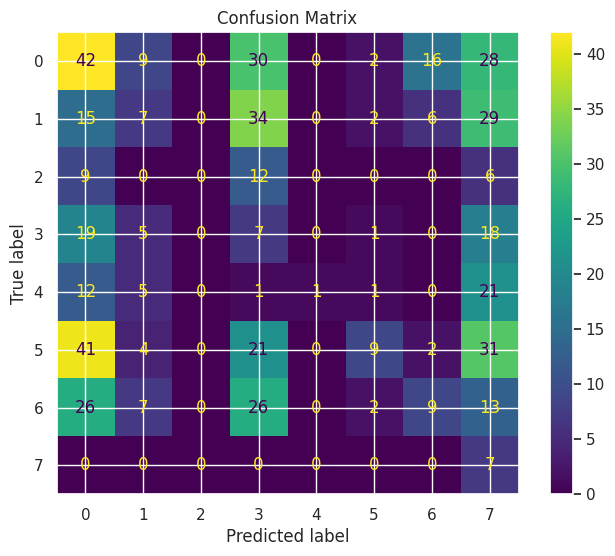

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_adam
------------------------------
TRAIN
Accuracy: 0.4524
Precision: 0.4601
Recall: 0.4524
F1: 0.4495
Kappa: 0.3316
Error Rate: 0.5476

TEST
Accuracy: 0.1063
Precision: 0.1052
Recall: 0.1063
F1: 0.0808
Kappa: -0.0080
Error Rate: 0.8937
Gap (overfitting): 0.3460

CV
Mean: 0.5972
Std: 0.0937
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



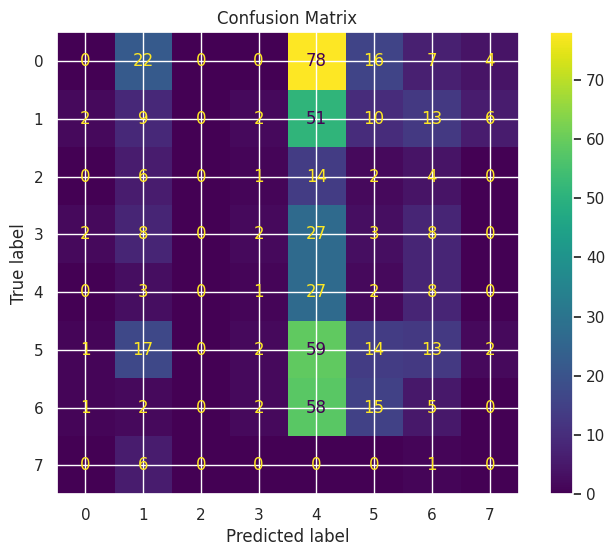

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4724
Precision: 0.4591
Recall: 0.4724
F1: 0.4419
Kappa: 0.3467
Error Rate: 0.5276

TEST
Accuracy: 0.1847
Precision: 0.1916
Recall: 0.1847
F1: 0.1062
Kappa: 0.0005
Error Rate: 0.8153
Gap (overfitting): 0.2877

CV
Mean: 0.4723
Std: 0.0231
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



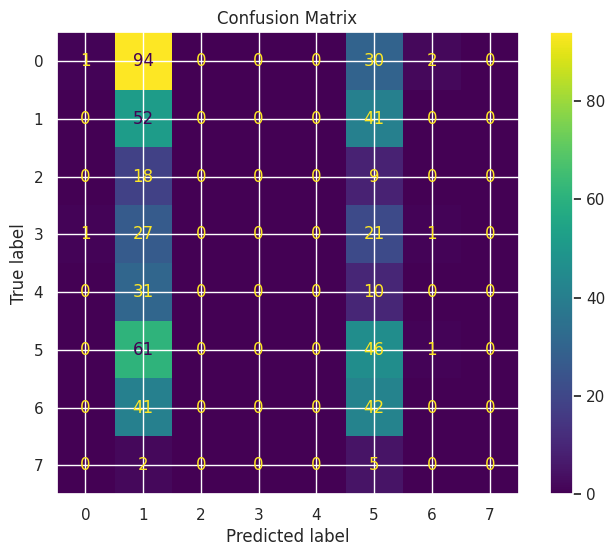

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.3731
Precision: 0.3080
Recall: 0.3731
F1: 0.3190
Kappa: 0.2201
Error Rate: 0.6269

TEST
Accuracy: 0.1922
Precision: 0.1100
Recall: 0.1922
F1: 0.1177
Kappa: -0.0246
Error Rate: 0.8078
Gap (overfitting): 0.1809

CV
Mean: 0.3821
Std: 0.0179
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



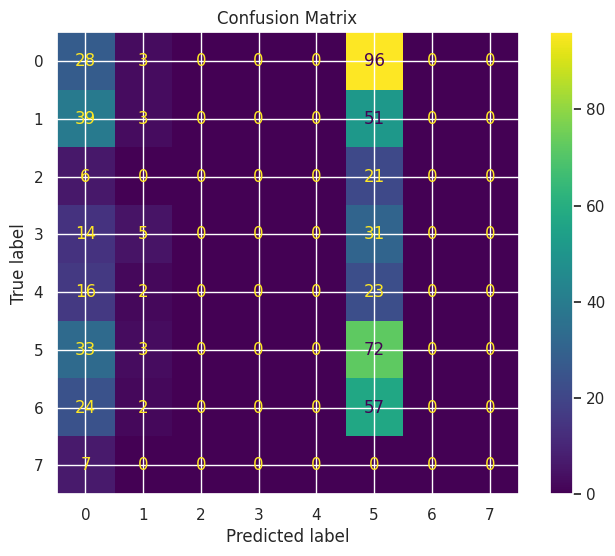

In [4]:
models_tcn_lstm = {}


# Para TCN-LSTM: tcn_channels=[8], lstm_hidden=8 (equivalente a hidden=30 total)
models_tcn_lstm['TCN_LSTM_rmsprop'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm['TCN_LSTM_adam'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm['TCN_LSTM_sgd_momentum'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm['TCN_LSTM_adam_lowLR'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_lstm, "tcn_lstm_experiments")

/tmp/ipykernel_718/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_30
------------------------------
TRAIN
Accuracy: 0.4307
Precision: 0.3567
Recall: 0.4307
F1: 0.3644
Kappa: 0.2877
Error Rate: 0.5693

TEST
Accuracy: 0.1791
Precision: 0.0941
Recall: 0.1791
F1: 0.1053
Kappa: -0.0467
Error Rate: 0.8209
Gap (overfitting): 0.2516

CV
Mean: 0.4555
Std: 0.0452
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



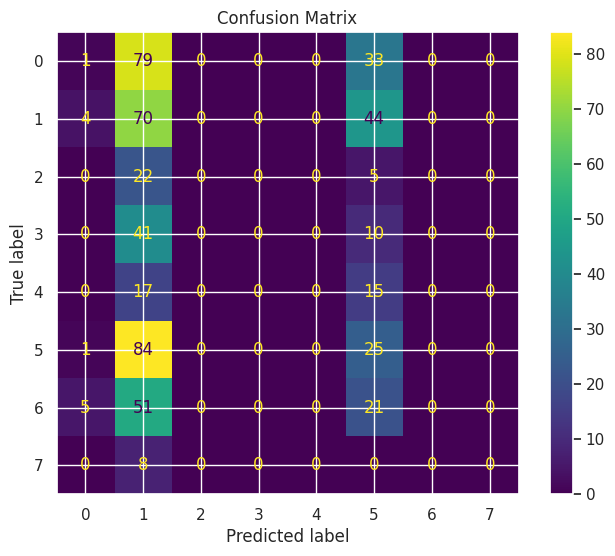

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_50
------------------------------
TRAIN
Accuracy: 0.5997
Precision: 0.5786
Recall: 0.5997
F1: 0.5827
Kappa: 0.5114
Error Rate: 0.4003

TEST
Accuracy: 0.1716
Precision: 0.2001
Recall: 0.1716
F1: 0.1058
Kappa: -0.0057
Error Rate: 0.8284
Gap (overfitting): 0.4280

CV
Mean: 0.6476
Std: 0.0729
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



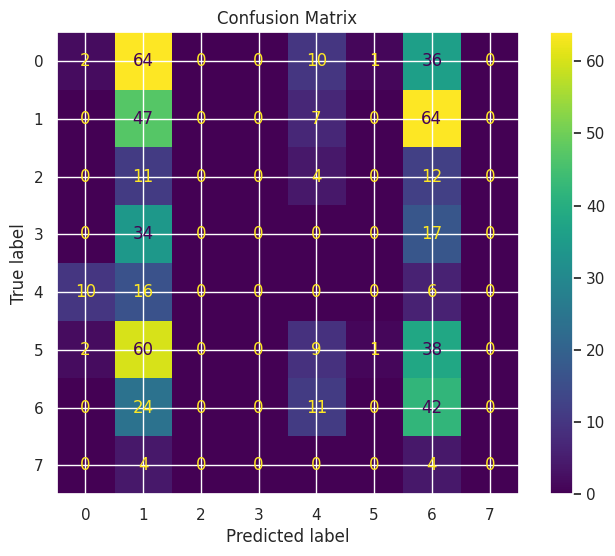

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LST_50_16
------------------------------
TRAIN
Accuracy: 0.6333
Precision: 0.5334
Recall: 0.6333
F1: 0.5705
Kappa: 0.5409
Error Rate: 0.3667

TEST
Accuracy: 0.1511
Precision: 0.0955
Recall: 0.1511
F1: 0.0959
Kappa: -0.0206
Error Rate: 0.8489
Gap (overfitting): 0.4822

CV
Mean: 0.6723
Std: 0.0730
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



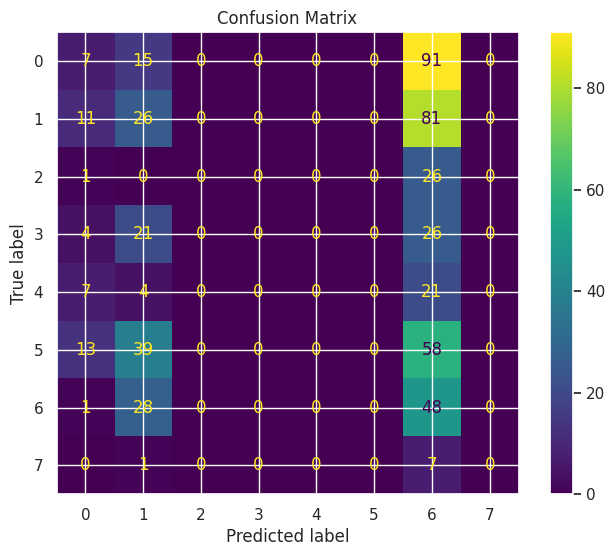

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_sgde3
------------------------------
TRAIN
Accuracy: 0.4107
Precision: 0.3526
Recall: 0.4107
F1: 0.3501
Kappa: 0.2628
Error Rate: 0.5893

TEST
Accuracy: 0.2687
Precision: 0.2441
Recall: 0.2687
F1: 0.1923
Kappa: 0.0711
Error Rate: 0.7313
Gap (overfitting): 0.1421

CV
Mean: 0.3905
Std: 0.0283
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.3, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



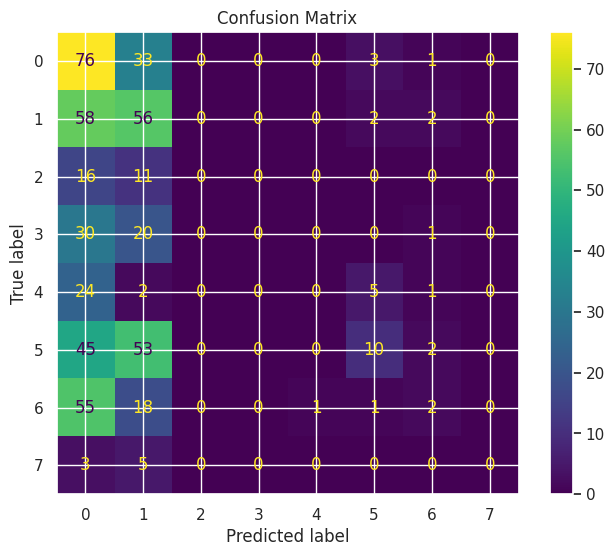

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTMsprop_30
------------------------------
TRAIN
Accuracy: 0.5596
Precision: 0.5970
Recall: 0.5596
F1: 0.5245
Kappa: 0.4581
Error Rate: 0.4404

TEST
Accuracy: 0.1175
Precision: 0.2057
Recall: 0.1175
F1: 0.0884
Kappa: 0.0353
Error Rate: 0.8825
Gap (overfitting): 0.4421

CV
Mean: 0.6465
Std: 0.1071
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



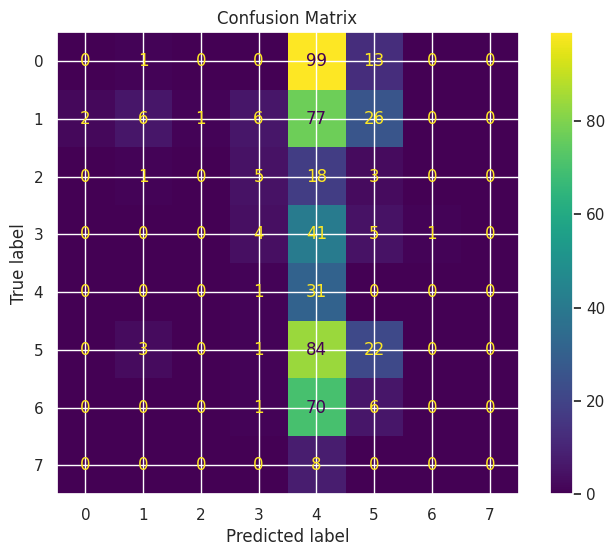

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTMsprop_50
------------------------------
TRAIN
Accuracy: 0.6437
Precision: 0.6761
Recall: 0.6437
F1: 0.6328
Kappa: 0.5636
Error Rate: 0.3563

TEST
Accuracy: 0.1437
Precision: 0.1340
Recall: 0.1437
F1: 0.0931
Kappa: 0.0315
Error Rate: 0.8563
Gap (overfitting): 0.5001

CV
Mean: 0.8090
Std: 0.1612
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



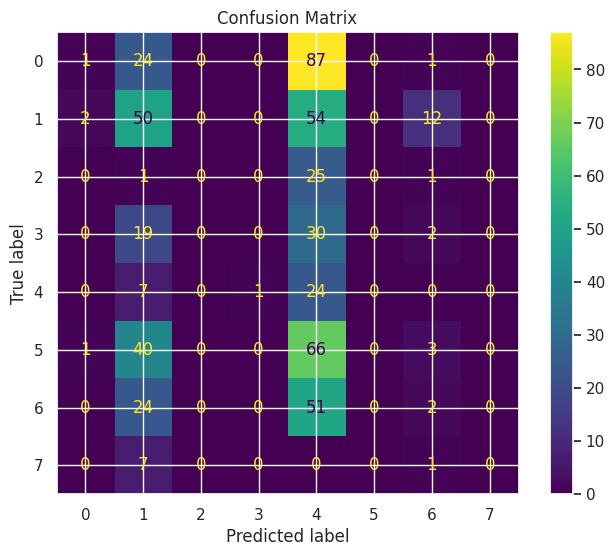

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTMprop_5016
------------------------------
TRAIN
Accuracy: 0.9752
Precision: 0.9763
Recall: 0.9752
F1: 0.9751
Kappa: 0.9699
Error Rate: 0.0248

TEST
Accuracy: 0.1660
Precision: 0.1687
Recall: 0.1660
F1: 0.1045
Kappa: -0.0230
Error Rate: 0.8340
Gap (overfitting): 0.8091

CV
Mean: 0.8616
Std: 0.1265
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



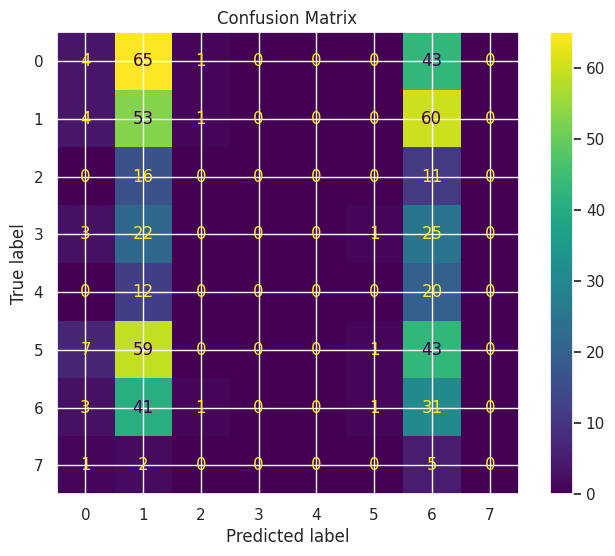

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_owLR_30
------------------------------
TRAIN
Accuracy: 0.4380
Precision: 0.3745
Recall: 0.4380
F1: 0.3694
Kappa: 0.2936
Error Rate: 0.5620

TEST
Accuracy: 0.1940
Precision: 0.0887
Recall: 0.1940
F1: 0.0917
Kappa: 0.0081
Error Rate: 0.8060
Gap (overfitting): 0.2439

CV
Mean: 0.4168
Std: 0.0442
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



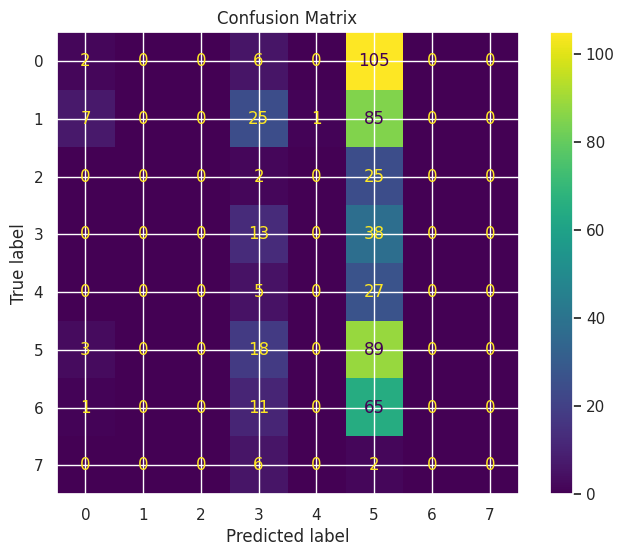

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTMlowLR_50
------------------------------
TRAIN
Accuracy: 0.5004
Precision: 0.5190
Recall: 0.5004
F1: 0.4760
Kappa: 0.3868
Error Rate: 0.4996

TEST
Accuracy: 0.1978
Precision: 0.1508
Recall: 0.1978
F1: 0.1273
Kappa: 0.0342
Error Rate: 0.8022
Gap (overfitting): 0.3026

CV
Mean: 0.5283
Std: 0.0656
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



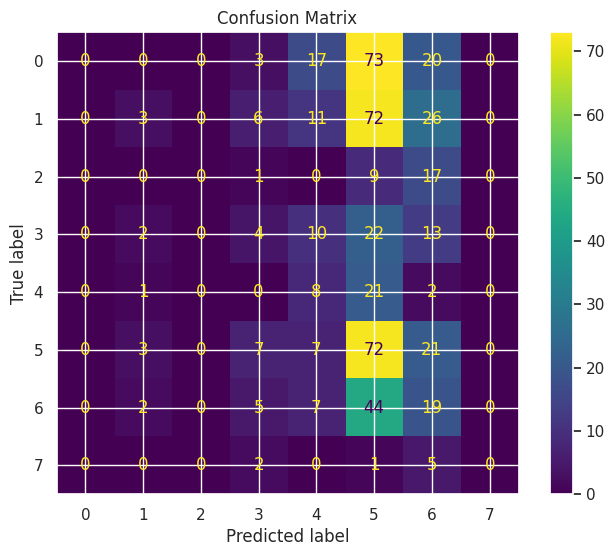

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTMowLR5016
------------------------------
TRAIN
Accuracy: 0.7046
Precision: 0.7016
Recall: 0.7046
F1: 0.6839
Kappa: 0.6348
Error Rate: 0.2954

TEST
Accuracy: 0.2071
Precision: 0.1807
Recall: 0.2071
F1: 0.1200
Kappa: 0.0269
Error Rate: 0.7929
Gap (overfitting): 0.4975

CV
Mean: 0.6835
Std: 0.0975
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



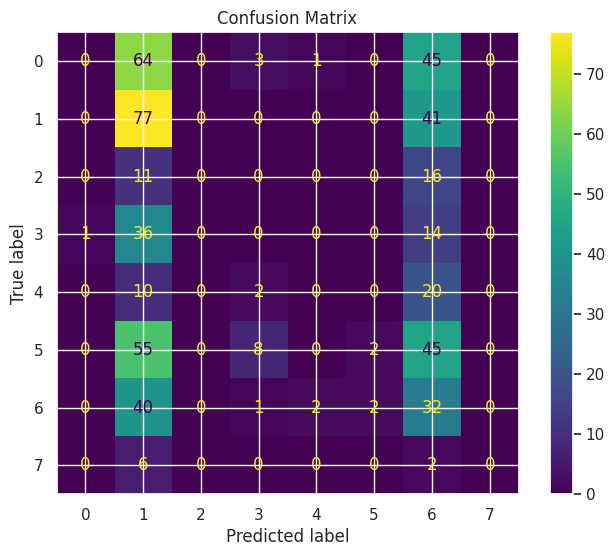

In [5]:
models_tcn_lstm_f1 = {}


# ============================================================
# 1º MELHOR: TCN_LSTM_sgd_momentum
# ============================================================


models_tcn_lstm_f1['TCN_LSTM_30'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f1['TCN_LSTM_50'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas TCN + 2 camadas LSTM (equivalente a 50_16)
models_tcn_lstm_f1['TCN_LST_50_16'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_tcn_lstm_f1['TCN_LSTM_sgde3'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.3, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: TCN_LSTM_rmsprop
# ============================================================


models_tcn_lstm_f1['TCN_LSTMsprop_30'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f1['TCN_LSTMsprop_50'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f1['TCN_LSTMprop_5016'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: TCN_LSTM_adam_lowLR
# ============================================================


models_tcn_lstm_f1['TCN_LSTM_owLR_30'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f1['TCN_LSTMlowLR_50'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f1['TCN_LSTMowLR5016'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_lstm_f1, "tcn_lstm_fase_1")


/tmp/ipykernel_718/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_solver_adam
------------------------------
TRAIN
Accuracy: 0.4131
Precision: 0.3544
Recall: 0.4131
F1: 0.3540
Kappa: 0.2577
Error Rate: 0.5869

TEST
Accuracy: 0.1082
Precision: 0.0846
Recall: 0.1082
F1: 0.0699
Kappa: -0.0252
Error Rate: 0.8918
Gap (overfitting): 0.3049

CV
Mean: 0.4179
Std: 0.0365
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



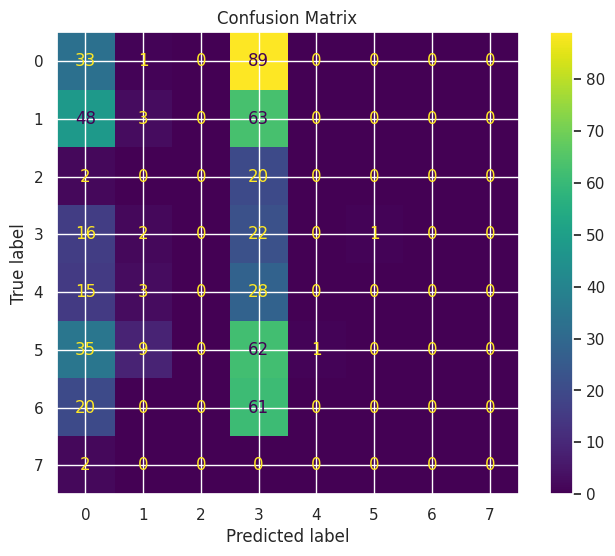

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_solver_sgd
------------------------------
TRAIN
Accuracy: 0.4380
Precision: 0.4638
Recall: 0.4380
F1: 0.3720
Kappa: 0.2966
Error Rate: 0.5620

TEST
Accuracy: 0.1847
Precision: 0.0833
Recall: 0.1847
F1: 0.0781
Kappa: -0.0284
Error Rate: 0.8153
Gap (overfitting): 0.2532

CV
Mean: 0.4588
Std: 0.0488
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



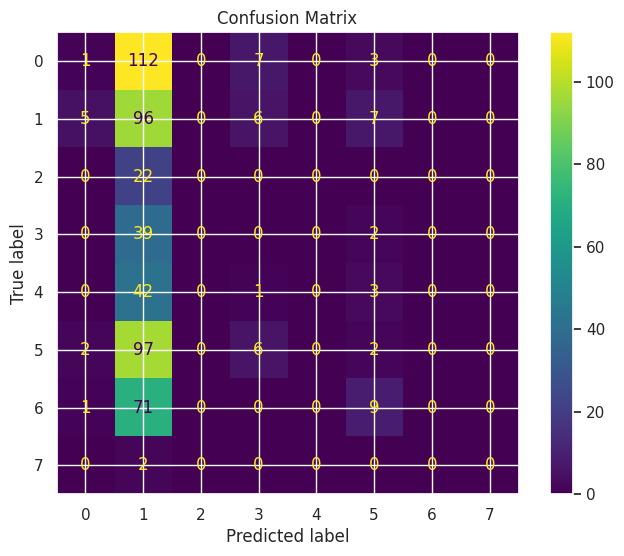

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_solver_rmsprop
------------------------------
TRAIN
Accuracy: 0.6517
Precision: 0.6371
Recall: 0.6517
F1: 0.6377
Kappa: 0.5705
Error Rate: 0.3483

TEST
Accuracy: 0.1604
Precision: 0.0516
Recall: 0.1604
F1: 0.0758
Kappa: -0.0151
Error Rate: 0.8396
Gap (overfitting): 0.4913

CV
Mean: 0.6549
Std: 0.1320
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



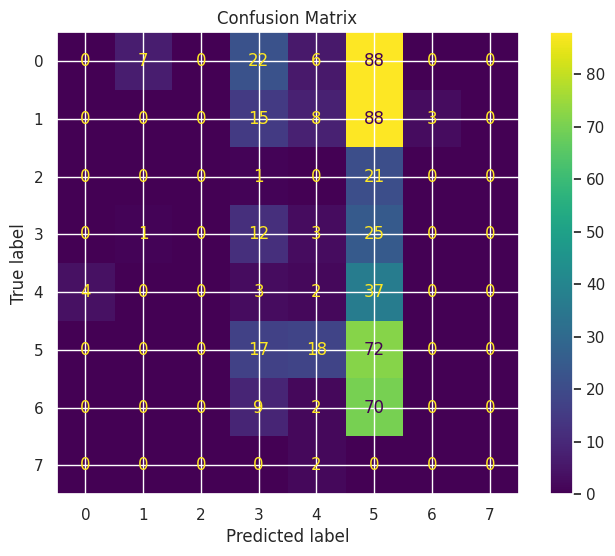

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_30
------------------------------
TRAIN
Accuracy: 0.4131
Precision: 0.3544
Recall: 0.4131
F1: 0.3540
Kappa: 0.2577
Error Rate: 0.5869

TEST
Accuracy: 0.1082
Precision: 0.0846
Recall: 0.1082
F1: 0.0699
Kappa: -0.0252
Error Rate: 0.8918
Gap (overfitting): 0.3049

CV
Mean: 0.4179
Std: 0.0365
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



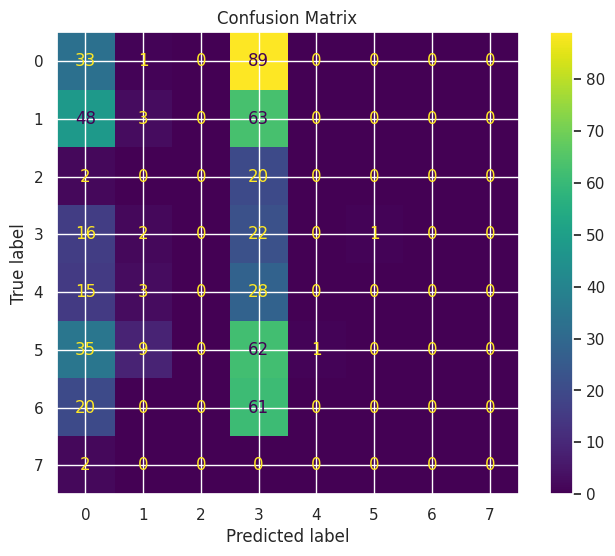

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_50
------------------------------
TRAIN
Accuracy: 0.4492
Precision: 0.4003
Recall: 0.4492
F1: 0.4169
Kappa: 0.3105
Error Rate: 0.5508

TEST
Accuracy: 0.0951
Precision: 0.0790
Recall: 0.0951
F1: 0.0514
Kappa: -0.0096
Error Rate: 0.9049
Gap (overfitting): 0.3540

CV
Mean: 0.4706
Std: 0.0620
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



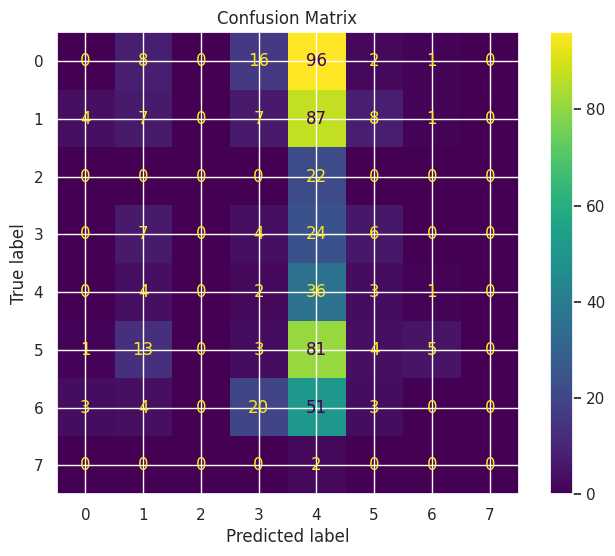

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_16
------------------------------
TRAIN
Accuracy: 0.7094
Precision: 0.7301
Recall: 0.7094
F1: 0.7007
Kappa: 0.6417
Error Rate: 0.2906

TEST
Accuracy: 0.0821
Precision: 0.1014
Recall: 0.0821
F1: 0.0362
Kappa: -0.0027
Error Rate: 0.9179
Gap (overfitting): 0.6273

CV
Mean: 0.7104
Std: 0.1240
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



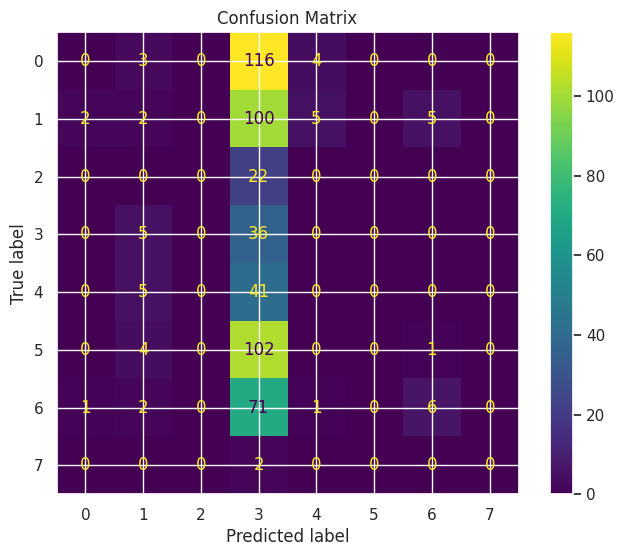

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_0
------------------------------
TRAIN
Accuracy: 0.4131
Precision: 0.3544
Recall: 0.4131
F1: 0.3540
Kappa: 0.2577
Error Rate: 0.5869

TEST
Accuracy: 0.1082
Precision: 0.0846
Recall: 0.1082
F1: 0.0699
Kappa: -0.0252
Error Rate: 0.8918
Gap (overfitting): 0.3049

CV
Mean: 0.4179
Std: 0.0365
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



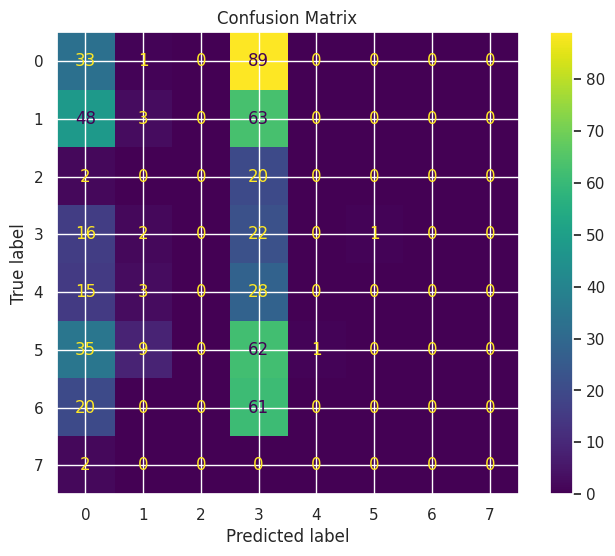

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_LSTM_1e-1
------------------------------
TRAIN
Accuracy: 0.4019
Precision: 0.3910
Recall: 0.4019
F1: 0.3333
Kappa: 0.2408
Error Rate: 0.5981

TEST
Accuracy: 0.1399
Precision: 0.1003
Recall: 0.1399
F1: 0.0926
Kappa: -0.0488
Error Rate: 0.8601
Gap (overfitting): 0.2620

CV
Mean: 0.3882
Std: 0.0267
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.1, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



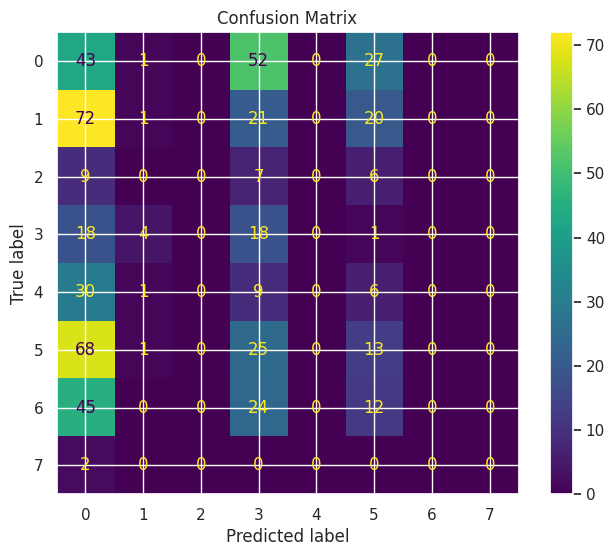

In [6]:
models_tcn_lstm_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_tcn_lstm_f2['TCN_LSTM_solver_adam'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f2['TCN_LSTM_solver_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f2['TCN_LSTM_solver_rmsprop'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================



# equivalente a hidden=30 (tcn=8, lstm=8)
models_tcn_lstm_f2['TCN_LSTM_30'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50 (tcn=16, lstm=16)
models_tcn_lstm_f2['TCN_LSTM_50'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas TCN + 2 camadas LSTM
models_tcn_lstm_f2['TCN_LSTM_16'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_tcn_lstm_f2['TCN_LSTM_0'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f2['TCN_LSTM_1e-1'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.1, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_lstm_f2, "tcn_lstm_fase_2")

/tmp/ipykernel_718/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd
------------------------------
TRAIN
Accuracy: 0.4259
Precision: 0.3934
Recall: 0.4259
F1: 0.3849
Kappa: 0.2946
Error Rate: 0.5741

TEST
Accuracy: 0.1940
Precision: 0.0836
Recall: 0.1940
F1: 0.0944
Kappa: 0.0020
Error Rate: 0.8060
Gap (overfitting): 0.2319

CV
Mean: 0.4006
Std: 0.0709
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



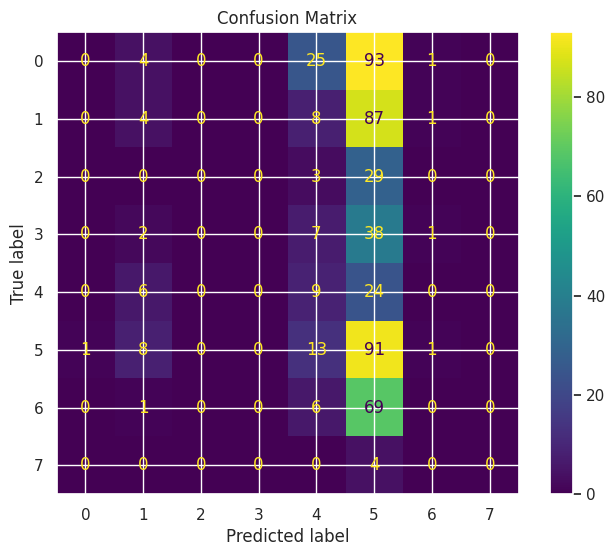

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_95
------------------------------
TRAIN
Accuracy: 0.3667
Precision: 0.3374
Recall: 0.3667
F1: 0.3294
Kappa: 0.2241
Error Rate: 0.6333

TEST
Accuracy: 0.0728
Precision: 0.1624
Recall: 0.0728
F1: 0.0168
Kappa: -0.0024
Error Rate: 0.9272
Gap (overfitting): 0.2939

CV
Mean: 0.4381
Std: 0.0952
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



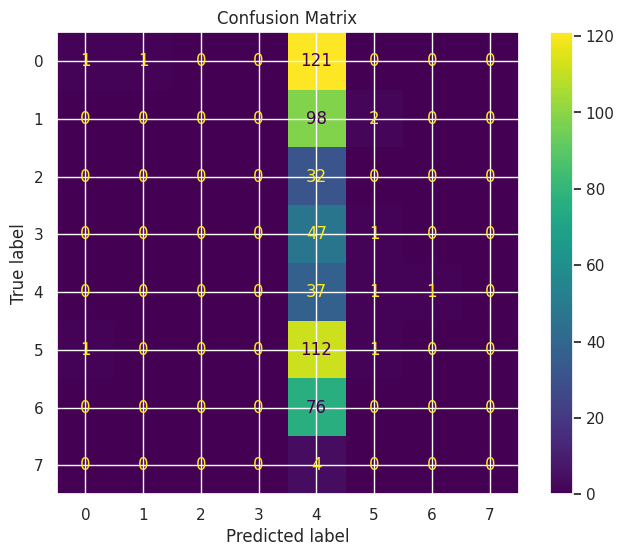

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd
------------------------------
TRAIN
Accuracy: 0.2954
Precision: 0.1952
Recall: 0.2954
F1: 0.2148
Kappa: 0.1193
Error Rate: 0.7046

TEST
Accuracy: 0.0821
Precision: 0.1105
Recall: 0.0821
F1: 0.0394
Kappa: -0.0038
Error Rate: 0.9179
Gap (overfitting): 0.2133

CV
Mean: 0.5916
Std: 0.0895
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



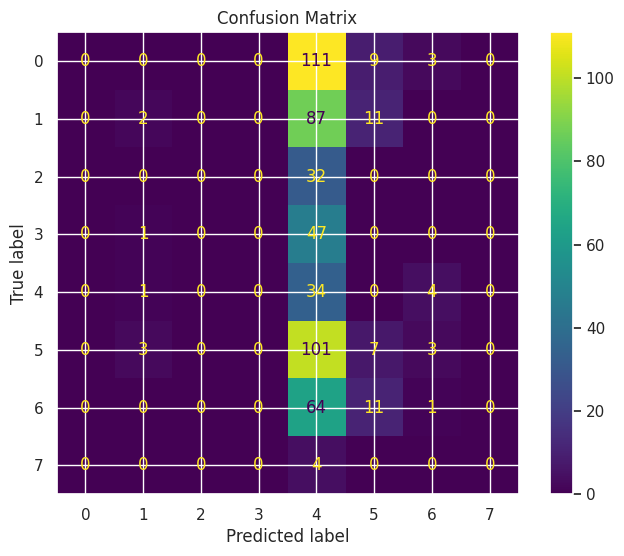

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd_95
------------------------------
TRAIN
Accuracy: 0.7318
Precision: 0.7469
Recall: 0.7318
F1: 0.7305
Kappa: 0.6766
Error Rate: 0.2682

TEST
Accuracy: 0.0728
Precision: 0.1677
Recall: 0.0728
F1: 0.0297
Kappa: -0.0051
Error Rate: 0.9272
Gap (overfitting): 0.6590

CV
Mean: 0.7070
Std: 0.1636
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



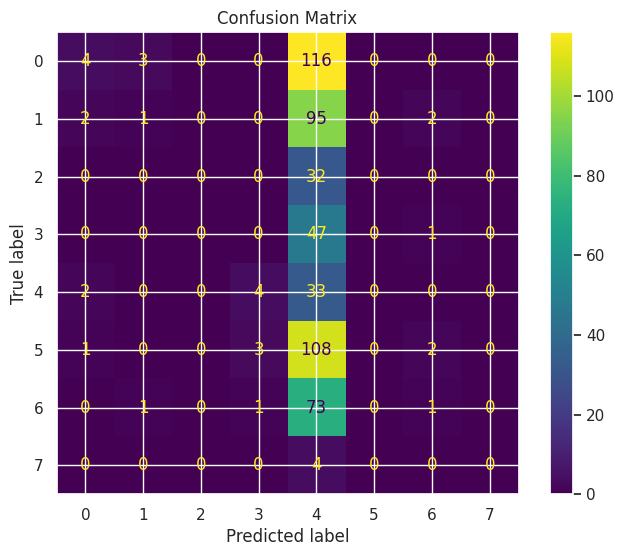

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_sgd
------------------------------
TRAIN
Accuracy: 0.6149
Precision: 0.5838
Recall: 0.6149
F1: 0.5724
Kappa: 0.5321
Error Rate: 0.3851

TEST
Accuracy: 0.2164
Precision: 0.1734
Recall: 0.2164
F1: 0.1764
Kappa: 0.0697
Error Rate: 0.7836
Gap (overfitting): 0.3985

CV
Mean: 0.6297
Std: 0.1303
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



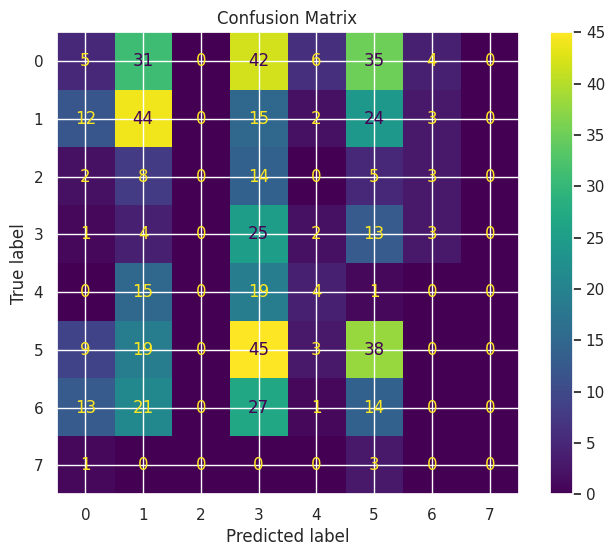

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_sgd_95
------------------------------
TRAIN
Accuracy: 0.8367
Precision: 0.8450
Recall: 0.8367
F1: 0.8318
Kappa: 0.8026
Error Rate: 0.1633

TEST
Accuracy: 0.1791
Precision: 0.1470
Recall: 0.1791
F1: 0.1603
Kappa: 0.0029
Error Rate: 0.8209
Gap (overfitting): 0.6576

CV
Mean: 0.7199
Std: 0.1610
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



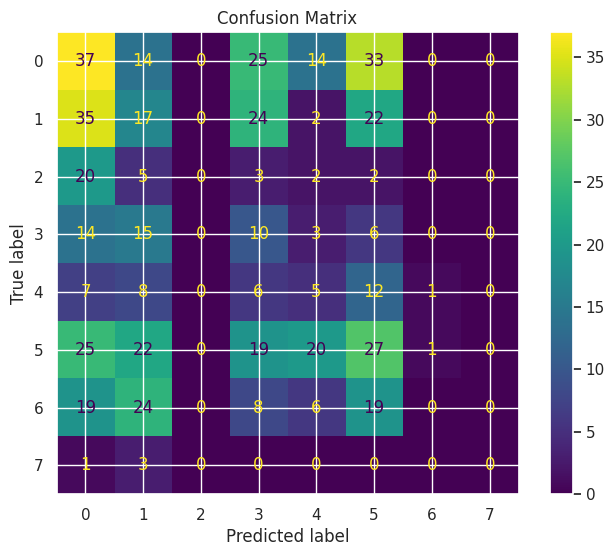

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_adame-4
------------------------------
TRAIN
Accuracy: 0.3227
Precision: 0.2555
Recall: 0.3227
F1: 0.2728
Kappa: 0.1686
Error Rate: 0.6773

TEST
Accuracy: 0.2108
Precision: 0.1801
Recall: 0.2108
F1: 0.0933
Kappa: -0.0016
Error Rate: 0.7892
Gap (overfitting): 0.1118

CV
Mean: 0.3412
Std: 0.0295
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



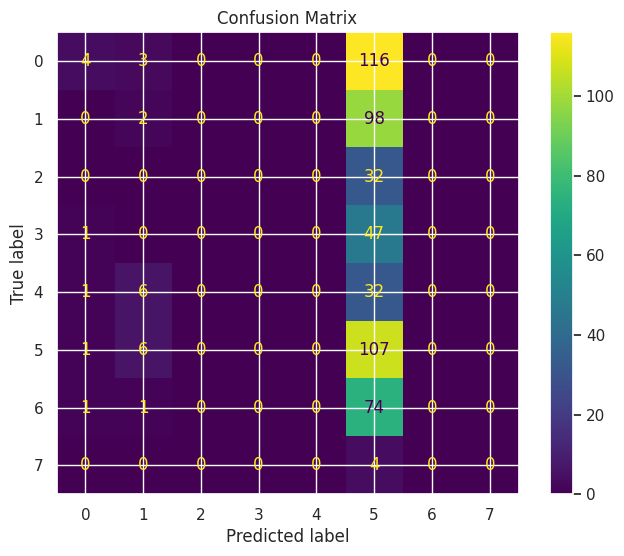

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_adame-4
------------------------------
TRAIN
Accuracy: 0.3939
Precision: 0.3752
Recall: 0.3939
F1: 0.3756
Kappa: 0.2615
Error Rate: 0.6061

TEST
Accuracy: 0.1101
Precision: 0.1115
Recall: 0.1101
F1: 0.0711
Kappa: 0.0011
Error Rate: 0.8899
Gap (overfitting): 0.2838

CV
Mean: 0.4235
Std: 0.0502
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'lstm_hidden': 16, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



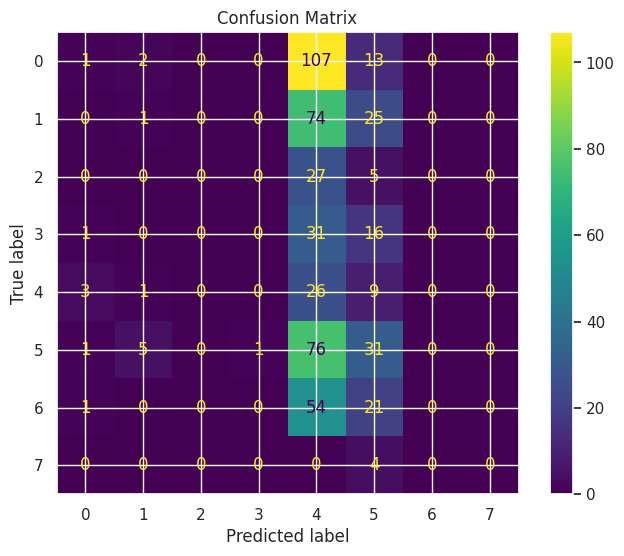

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_adame-4
------------------------------
TRAIN
Accuracy: 0.3891
Precision: 0.3394
Recall: 0.3891
F1: 0.3335
Kappa: 0.2433
Error Rate: 0.6109

TEST
Accuracy: 0.2332
Precision: 0.0979
Recall: 0.2332
F1: 0.1045
Kappa: 0.0060
Error Rate: 0.7668
Gap (overfitting): 0.1559

CV
Mean: 0.4146
Std: 0.0301
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1, 2], 'lstm_hidden': 16, 'lstm_layers': 2, 'lstm_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



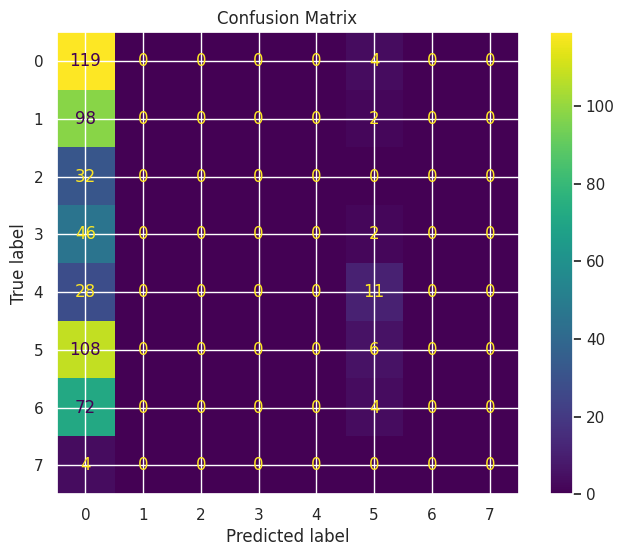

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd2
------------------------------
TRAIN
Accuracy: 0.3563
Precision: 0.3227
Recall: 0.3563
F1: 0.2915
Kappa: 0.2080
Error Rate: 0.6437

TEST
Accuracy: 0.2052
Precision: 0.1844
Recall: 0.2052
F1: 0.0851
Kappa: -0.0078
Error Rate: 0.7948
Gap (overfitting): 0.1511

CV
Mean: 0.3429
Std: 0.0269
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



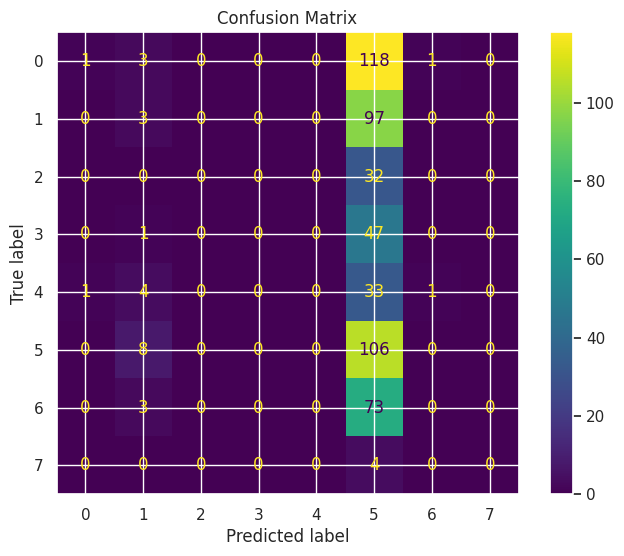

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgdowLR
------------------------------
TRAIN
Accuracy: 0.2626
Precision: 0.1565
Recall: 0.2626
F1: 0.1960
Kappa: 0.0781
Error Rate: 0.7374

TEST
Accuracy: 0.2313
Precision: 0.1906
Recall: 0.2313
F1: 0.0964
Kappa: 0.0037
Error Rate: 0.7687
Gap (overfitting): 0.0313

CV
Mean: 0.2431
Std: 0.0208
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



OSError: [Errno 36] File name too long: "Classification/tcn_lstm_fase_3/images/confusion_matrix_6xN+4xS-1_05+0_95+1_1+0_9_TCN_LSTM_Hybrid(epochs=500, fc_hidden=(), input_size=21, learning_rate=0.0001,\n                lstm_dropout=0.0, lstm_hidden=8, solver='sgd', tcn_channels=[8],\n                tcn_dilations=[1], tcn_dropout=0.0).png"

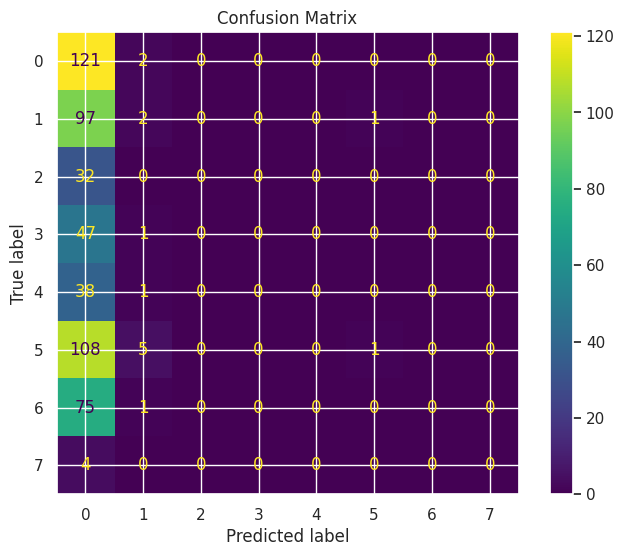

In [7]:
models_tcn_lstm_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_tcn_lstm_f3['F2_30_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_30_sgd_95'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_sgd_95'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_16_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_16_sgd_95'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_tcn_lstm_f3['F2_30_adame-4'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_adame-4'] = TCN_LSTM_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    lstm_hidden=16, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f3['F2_50_16_adame-4'] = TCN_LSTM_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1, 2],
    lstm_hidden=16, lstm_layers=2, lstm_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_tcn_lstm_f3['F2_30_sgd2'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)



models_tcn_lstm_f3['F2_30_sgdowLR'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_lstm_f3, "tcn_lstm_fase_3")


/tmp/ipykernel_520/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-30_sgd
------------------------------
TRAIN
Accuracy: 0.4171
Precision: 0.3462
Recall: 0.4171
F1: 0.3648
Kappa: 0.2756
Error Rate: 0.5829

TEST
Accuracy: 0.1679
Precision: 0.1503
Recall: 0.1679
F1: 0.1264
Kappa: -0.0147
Error Rate: 0.8321
Gap (overfitting): 0.2492

CV
Mean: 0.4493
Std: 0.0479
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



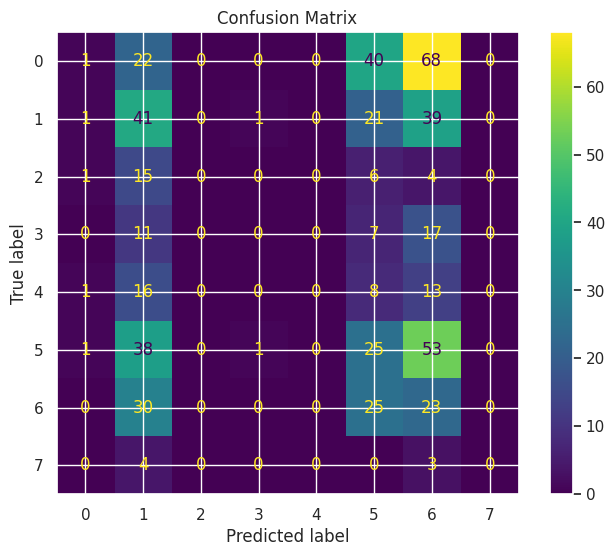

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_1_sgd
------------------------------
TRAIN
Accuracy: 0.4171
Precision: 0.3636
Recall: 0.4171
F1: 0.3791
Kappa: 0.2758
Error Rate: 0.5829

TEST
Accuracy: 0.2071
Precision: 0.2458
Recall: 0.2071
F1: 0.1392
Kappa: 0.0170
Error Rate: 0.7929
Gap (overfitting): 0.2100

CV
Mean: 0.4235
Std: 0.0426
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.1, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



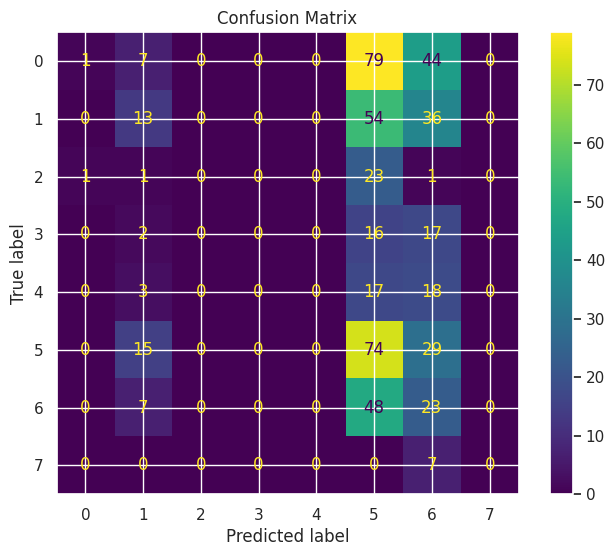

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_2_sgd
------------------------------
TRAIN
Accuracy: 0.3939
Precision: 0.3409
Recall: 0.3939
F1: 0.3500
Kappa: 0.2475
Error Rate: 0.6061

TEST
Accuracy: 0.2351
Precision: 0.1657
Recall: 0.2351
F1: 0.1293
Kappa: 0.0252
Error Rate: 0.7649
Gap (overfitting): 0.1588

CV
Mean: 0.3854
Std: 0.0202
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'lstm_hidden': 8, 'lstm_layers': 1, 'lstm_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



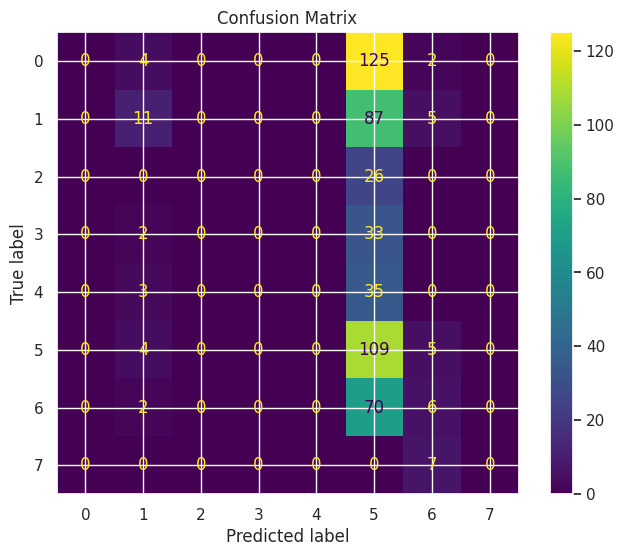

In [5]:
models_tcn_lstm_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================


models_tcn_lstm_f4['F3_30_lr1e-30_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_tcn_lstm_f4['F3_30_lr1e-3_1_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.1, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.1, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_lstm_f4['F3_30_lr1e-3_2_sgd'] = TCN_LSTM_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    lstm_hidden=8, lstm_layers=1, lstm_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)
main(models_tcn_lstm_f4, "tcnlstmf4")



In [4]:
class TCN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """TCN para extrair padrões temporais + GRU para dependências sequenciais"""

    def __init__(self,
                 tcn_channels=[16, 32],
                 tcn_kernel=3,
                 tcn_dropout=0.2,
                 tcn_dilations=[1, 2],
                 gru_hidden=16,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.tcn_channels = tcn_channels
        self.tcn_kernel = tcn_kernel
        self.tcn_dropout = tcn_dropout
        self.tcn_dilations = tcn_dilations
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class TCN_GRU_Model(nn.Module):
            def __init__(self, input_size, tcn_channels, tcn_kernel, tcn_dilations, tcn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(TCN_GRU_Model, self).__init__()

                # TCN
                tcn_layers = []
                prev_channels = 1

                for i, (out_channels, dilation) in enumerate(zip(tcn_channels, tcn_dilations)):
                    tcn_layers.append(
                        nn.Conv1d(prev_channels, out_channels, tcn_kernel,
                                  padding='same', dilation=dilation)
                    )
                    tcn_layers.append(nn.BatchNorm1d(out_channels))
                    tcn_layers.append(nn.ReLU())
                    tcn_layers.append(nn.Dropout(tcn_dropout))
                    prev_channels = out_channels

                self.tcn = nn.Sequential(*tcn_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_channels,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(tcn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, 1, features)
                x = self.tcn(x)  # (batch, channels, features)
                x = x.permute(0, 2, 1)  # (batch, features, channels)

                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return TCN_GRU_Model(
            input_size=self.input_size,
            tcn_channels=self.tcn_channels,
            tcn_kernel=self.tcn_kernel,
            tcn_dilations=self.tcn_dilations,
            tcn_dropout=self.tcn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
               # print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'tcn_channels': self.tcn_channels,
            'tcn_kernel': self.tcn_kernel,
            'tcn_dropout': self.tcn_dropout,
            'tcn_dilations': self.tcn_dilations,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_520/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.6861
Precision: 0.6549
Recall: 0.6861
F1: 0.6631
Kappa: 0.6145
Error Rate: 0.3139

TEST
Accuracy: 0.1679
Precision: 0.3033
Recall: 0.1679
F1: 0.0808
Kappa: -0.0219
Error Rate: 0.8321
Gap (overfitting): 0.5182

CV
Mean: 0.6403
Std: 0.0789
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



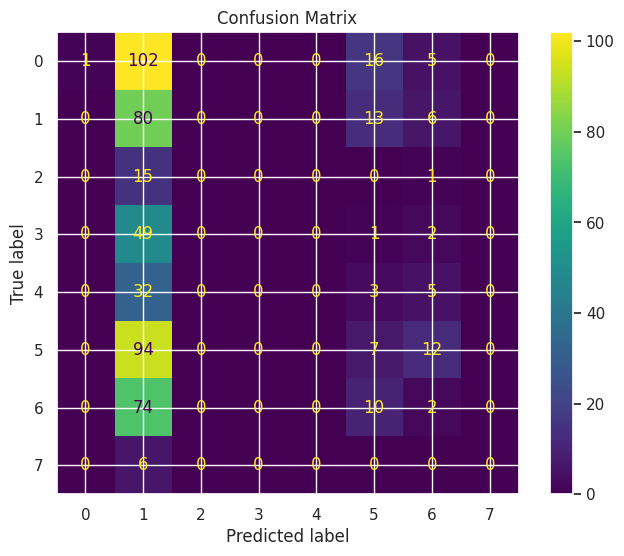

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_adam
------------------------------
TRAIN
Accuracy: 0.6685
Precision: 0.6796
Recall: 0.6685
F1: 0.6550
Kappa: 0.5936
Error Rate: 0.3315

TEST
Accuracy: 0.1138
Precision: 0.1544
Recall: 0.1138
F1: 0.0532
Kappa: 0.0057
Error Rate: 0.8862
Gap (overfitting): 0.5547

CV
Mean: 0.6443
Std: 0.0901
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



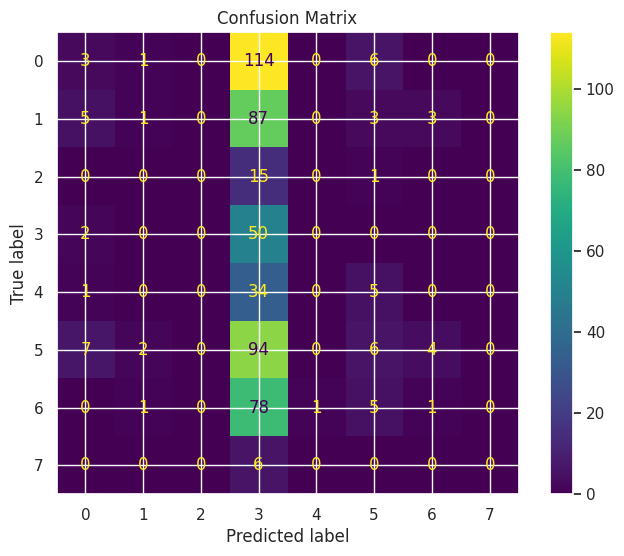

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.5084
Precision: 0.4570
Recall: 0.5084
F1: 0.4707
Kappa: 0.3858
Error Rate: 0.4916

TEST
Accuracy: 0.1716
Precision: 0.0951
Recall: 0.1716
F1: 0.1129
Kappa: 0.0386
Error Rate: 0.8284
Gap (overfitting): 0.3368

CV
Mean: 0.4538
Std: 0.0380
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



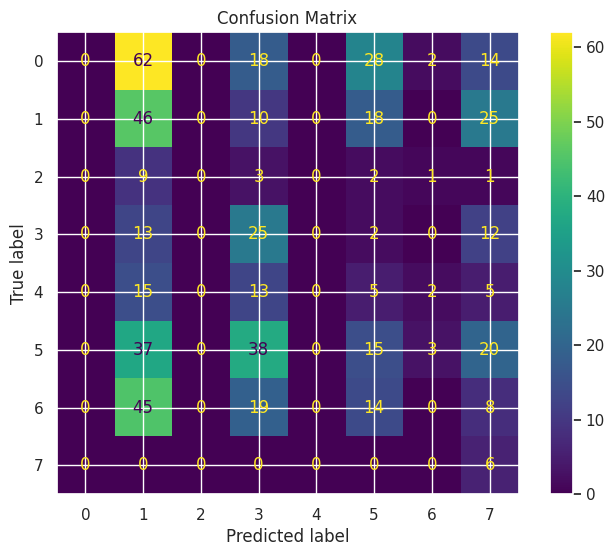

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.3755
Precision: 0.2896
Recall: 0.3755
F1: 0.3111
Kappa: 0.2185
Error Rate: 0.6245

TEST
Accuracy: 0.0299
Precision: 0.0851
Recall: 0.0299
F1: 0.0301
Kappa: -0.0060
Error Rate: 0.9701
Gap (overfitting): 0.3456

CV
Mean: 0.3905
Std: 0.0317
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



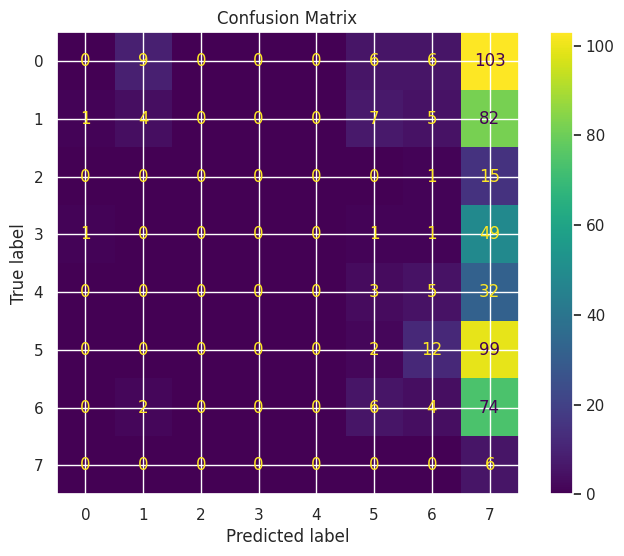

In [7]:
models_tcn_gru = {}


# Para TCN-GRU: tcn_channels=[8], gru_hidden=8 (equivalente a hidden=30 total)
models_tcn_gru['TCN_GRU_rmsprop'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru['TCN_GRU_adam'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru['TCN_GRU_sgd_momentum'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru['TCN_GRU_adam_lowLR'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru, "tcn_grus")

/tmp/ipykernel_520/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd_30
------------------------------
TRAIN
Accuracy: 0.3995
Precision: 0.3926
Recall: 0.3995
F1: 0.3791
Kappa: 0.2620
Error Rate: 0.6005

TEST
Accuracy: 0.0970
Precision: 0.0917
Recall: 0.0970
F1: 0.0333
Kappa: -0.0042
Error Rate: 0.9030
Gap (overfitting): 0.3025

CV
Mean: 0.3731
Std: 0.0311
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



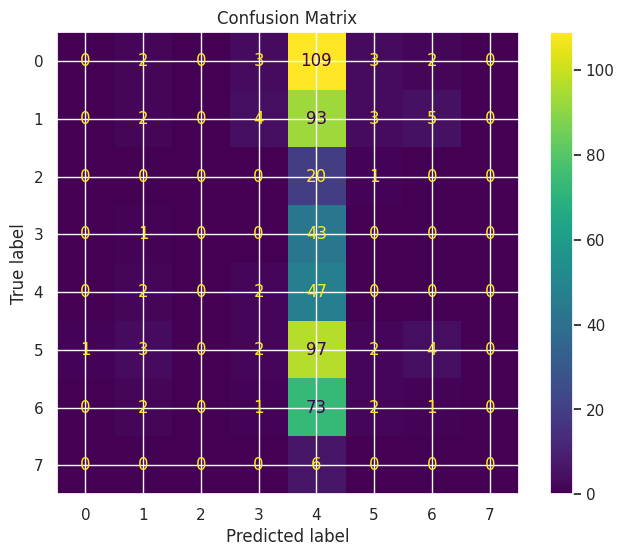

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd_50
------------------------------
TRAIN
Accuracy: 0.5300
Precision: 0.4656
Recall: 0.5300
F1: 0.4927
Kappa: 0.4214
Error Rate: 0.4700

TEST
Accuracy: 0.1250
Precision: 0.1181
Recall: 0.1250
F1: 0.0806
Kappa: 0.0165
Error Rate: 0.8750
Gap (overfitting): 0.4050

CV
Mean: 0.5176
Std: 0.1077
------------------------------
Model params:
{'tcn_channels': [8, 8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



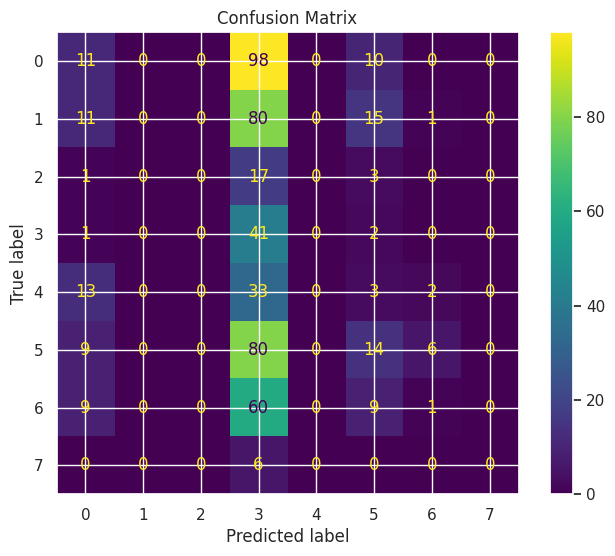

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd_1e3
------------------------------
TRAIN
Accuracy: 0.3259
Precision: 0.2634
Recall: 0.3259
F1: 0.2672
Kappa: 0.1599
Error Rate: 0.6741

TEST
Accuracy: 0.0896
Precision: 0.1214
Recall: 0.0896
F1: 0.0472
Kappa: -0.0061
Error Rate: 0.9104
Gap (overfitting): 0.2363

CV
Mean: 0.3356
Std: 0.0184
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.3, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



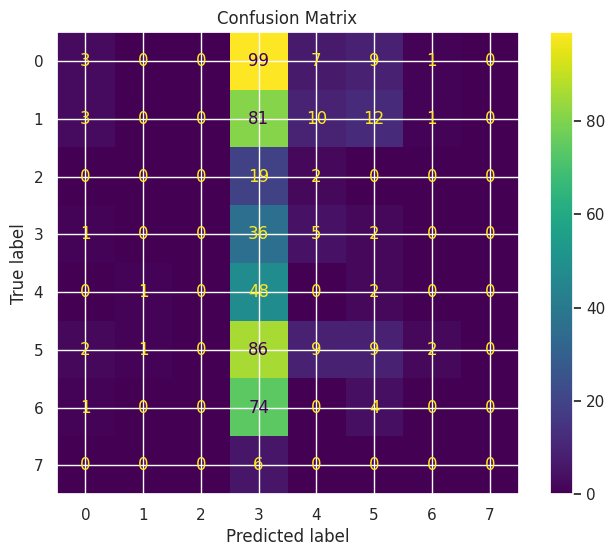

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd_5e3
------------------------------
TRAIN
Accuracy: 0.2898
Precision: 0.2070
Recall: 0.2898
F1: 0.2328
Kappa: 0.1083
Error Rate: 0.7102

TEST
Accuracy: 0.1474
Precision: 0.0959
Recall: 0.1474
F1: 0.0826
Kappa: 0.0015
Error Rate: 0.8526
Gap (overfitting): 0.1424

CV
Mean: 0.3003
Std: 0.0074
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.5, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.5, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



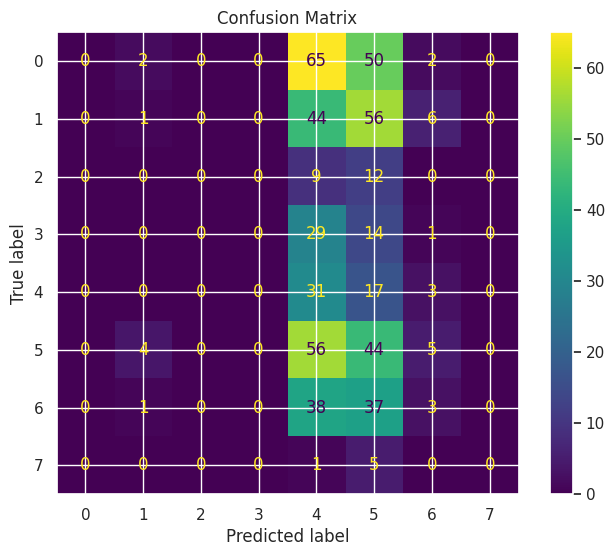


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRUprop_30
------------------------------
TRAIN
Accuracy: 0.6213
Precision: 0.6189
Recall: 0.6213
F1: 0.6124
Kappa: 0.5422
Error Rate: 0.3787

TEST
Accuracy: 0.1082
Precision: 0.2270
Recall: 0.1082
F1: 0.1010
Kappa: 0.0031
Error Rate: 0.8918
Gap (overfitting): 0.5131

CV
Mean: 0.5462
Std: 0.1087
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



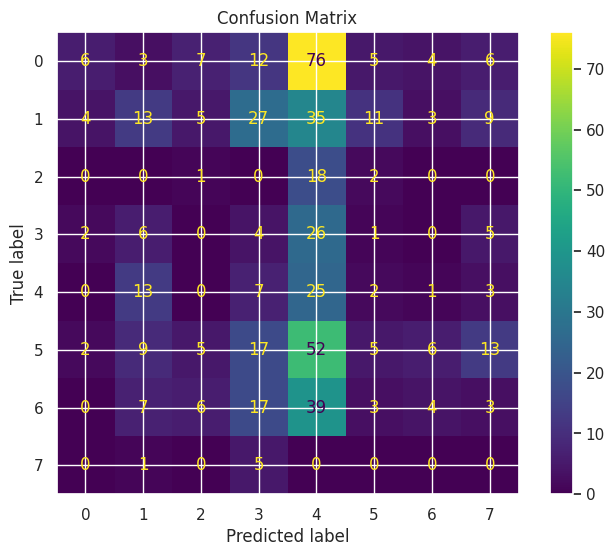

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRUprop_50_8
------------------------------
TRAIN
Accuracy: 0.6125
Precision: 0.6685
Recall: 0.6125
F1: 0.6050
Kappa: 0.5250
Error Rate: 0.3875

TEST
Accuracy: 0.1716
Precision: 0.1124
Recall: 0.1716
F1: 0.1216
Kappa: -0.0260
Error Rate: 0.8284
Gap (overfitting): 0.4408

CV
Mean: 0.6543
Std: 0.1394
------------------------------
Model params:
{'tcn_channels': [8, 8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



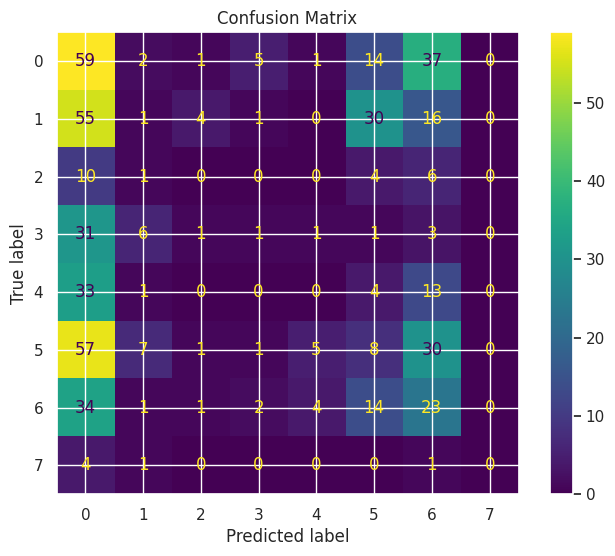

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRUadamlowL30
------------------------------
TRAIN
Accuracy: 0.3515
Precision: 0.3064
Recall: 0.3515
F1: 0.3135
Kappa: 0.1985
Error Rate: 0.6485

TEST
Accuracy: 0.1157
Precision: 0.1543
Recall: 0.1157
F1: 0.0867
Kappa: 0.0116
Error Rate: 0.8843
Gap (overfitting): 0.2358

CV
Mean: 0.3697
Std: 0.0105
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



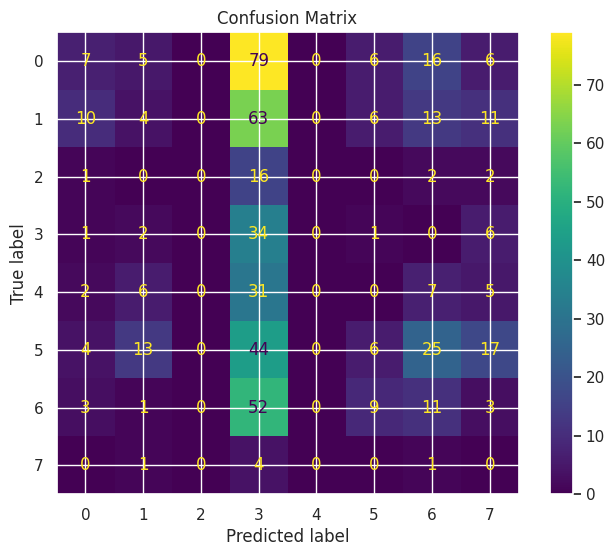

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_adamlowL08
------------------------------
TRAIN
Accuracy: 0.4315
Precision: 0.3635
Recall: 0.4315
F1: 0.3774
Kappa: 0.2942
Error Rate: 0.5685

TEST
Accuracy: 0.1381
Precision: 0.1329
Recall: 0.1381
F1: 0.1140
Kappa: -0.0250
Error Rate: 0.8619
Gap (overfitting): 0.2935

CV
Mean: 0.4706
Std: 0.0740
------------------------------
Model params:
{'tcn_channels': [8, 8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



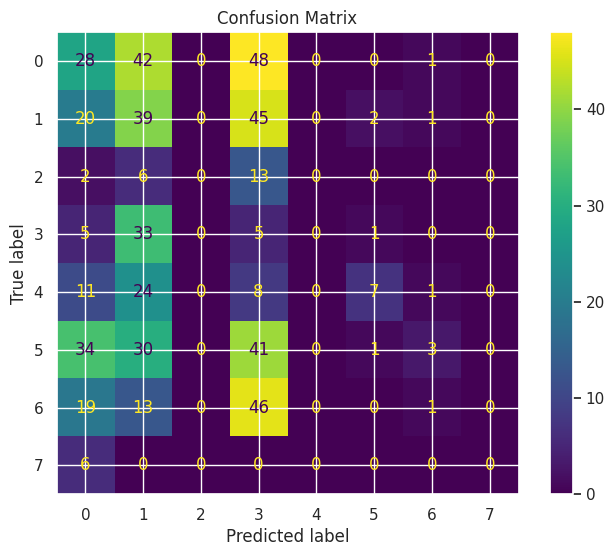

In [8]:
models_tcn_gru_f1 = {}


# ============================================================
# 1º MELHOR: TCN_GRU_sgd_momentum
# ============================================================


models_tcn_gru_f1['TCN_GRU_sgd_30'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas TCN + 2 camadas GRU (equivalente a 50_8)
models_tcn_gru_f1['TCN_GRU_sgd_50'] = TCN_GRU_Hybrid(
    tcn_channels=[8, 8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_tcn_gru_f1['TCN_GRU_sgd_1e3'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.3, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f1['TCN_GRU_sgd_5e3'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.5, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.5, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: TCN_GRU_rmsprop
# ============================================================


models_tcn_gru_f1['TCN_GRUprop_30'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f1['TCN_GRUprop_50_8'] = TCN_GRU_Hybrid(
    tcn_channels=[8, 8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(8,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: TCN_GRU_adam_lowLR
# ============================================================


models_tcn_gru_f1['TCN_GRUadamlowL30'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f1['TCN_GRU_adamlowL08'] = TCN_GRU_Hybrid(
    tcn_channels=[8, 8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru_f1, "tcn_gru1")

/tmp/ipykernel_520/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_adam
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3045
Recall: 0.3475
F1: 0.2928
Kappa: 0.1900
Error Rate: 0.6525

TEST
Accuracy: 0.0205
Precision: 0.1425
Recall: 0.0205
F1: 0.0176
Kappa: -0.0093
Error Rate: 0.9795
Gap (overfitting): 0.3270

CV
Mean: 0.3580
Std: 0.0241
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



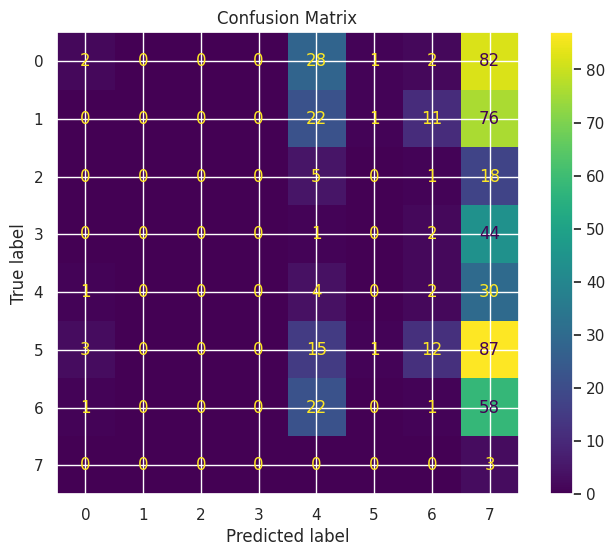

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_sgd
------------------------------
TRAIN
Accuracy: 0.4067
Precision: 0.4194
Recall: 0.4067
F1: 0.3800
Kappa: 0.2676
Error Rate: 0.5933

TEST
Accuracy: 0.0821
Precision: 0.0778
Recall: 0.0821
F1: 0.0387
Kappa: 0.0011
Error Rate: 0.9179
Gap (overfitting): 0.3246

CV
Mean: 0.4196
Std: 0.0368
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



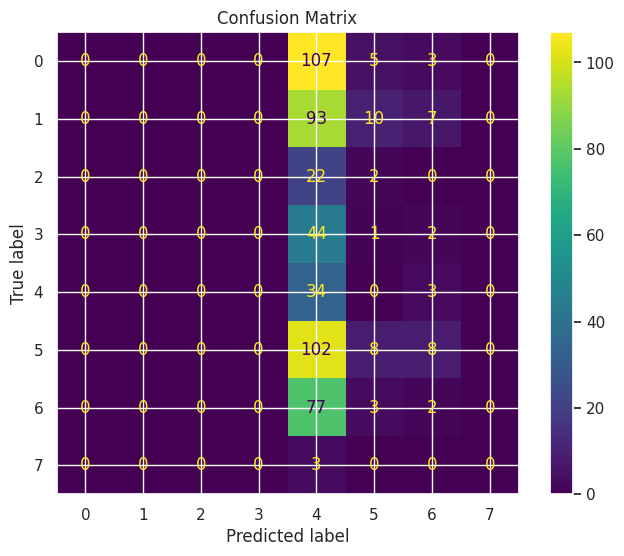

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.6229
Precision: 0.6140
Recall: 0.6229
F1: 0.5969
Kappa: 0.5365
Error Rate: 0.3771

TEST
Accuracy: 0.0336
Precision: 0.0671
Recall: 0.0336
F1: 0.0273
Kappa: -0.0273
Error Rate: 0.9664
Gap (overfitting): 0.5893

CV
Mean: 0.5423
Std: 0.1185
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



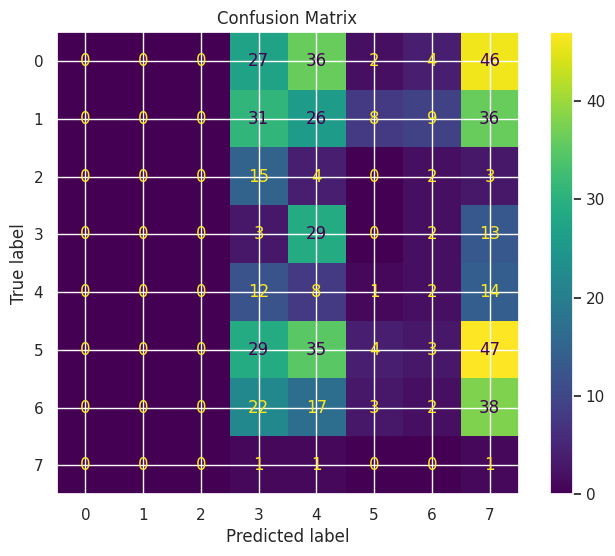

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_10
------------------------------
TRAIN
Accuracy: 0.3347
Precision: 0.2939
Recall: 0.3347
F1: 0.2814
Kappa: 0.1722
Error Rate: 0.6653

TEST
Accuracy: 0.0149
Precision: 0.0784
Recall: 0.0149
F1: 0.0159
Kappa: -0.0026
Error Rate: 0.9851
Gap (overfitting): 0.3197

CV
Mean: 0.3412
Std: 0.0195
------------------------------
Model params:
{'tcn_channels': [5], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 5, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



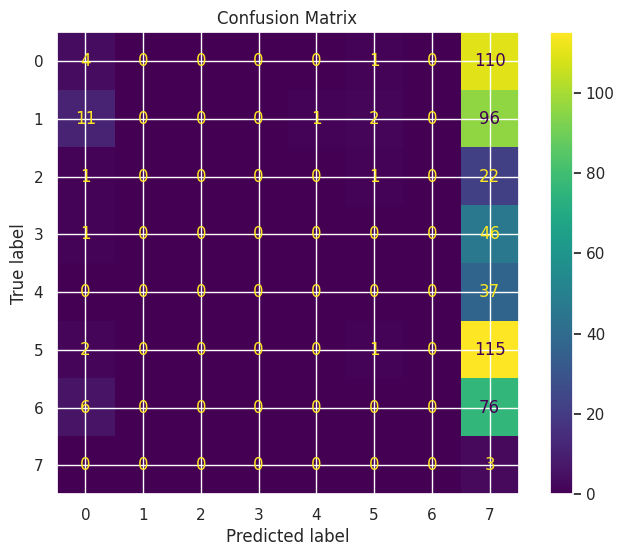

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_30
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3045
Recall: 0.3475
F1: 0.2928
Kappa: 0.1900
Error Rate: 0.6525

TEST
Accuracy: 0.0205
Precision: 0.1425
Recall: 0.0205
F1: 0.0176
Kappa: -0.0093
Error Rate: 0.9795
Gap (overfitting): 0.3270

CV
Mean: 0.3580
Std: 0.0241
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



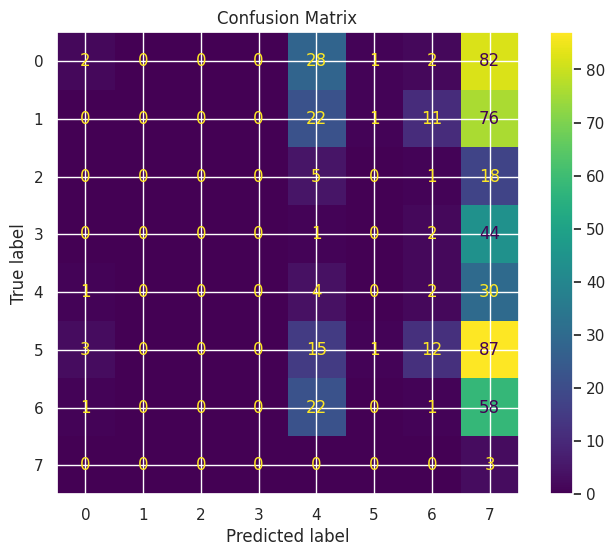

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU__50
------------------------------
TRAIN
Accuracy: 0.4123
Precision: 0.4010
Recall: 0.4123
F1: 0.3641
Kappa: 0.2763
Error Rate: 0.5877

TEST
Accuracy: 0.1642
Precision: 0.1689
Recall: 0.1642
F1: 0.1208
Kappa: 0.0197
Error Rate: 0.8358
Gap (overfitting): 0.2482

CV
Mean: 0.4812
Std: 0.0724
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



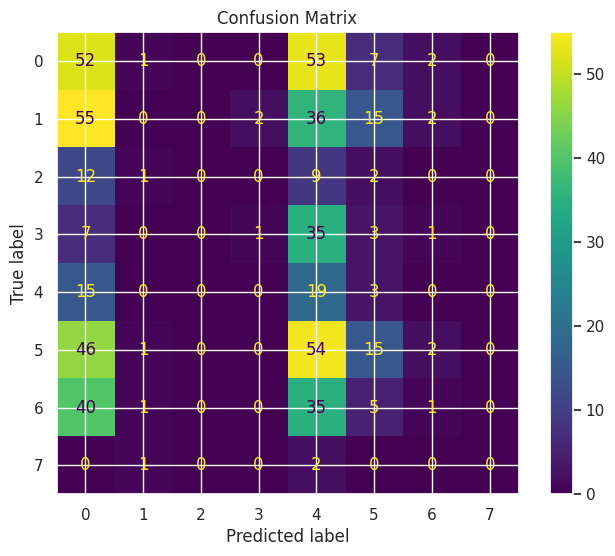

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_50_16
------------------------------
TRAIN
Accuracy: 0.6149
Precision: 0.5441
Recall: 0.6149
F1: 0.5731
Kappa: 0.5263
Error Rate: 0.3851

TEST
Accuracy: 0.1530
Precision: 0.2282
Recall: 0.1530
F1: 0.0802
Kappa: -0.0017
Error Rate: 0.8470
Gap (overfitting): 0.4619

CV
Mean: 0.5871
Std: 0.1321
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



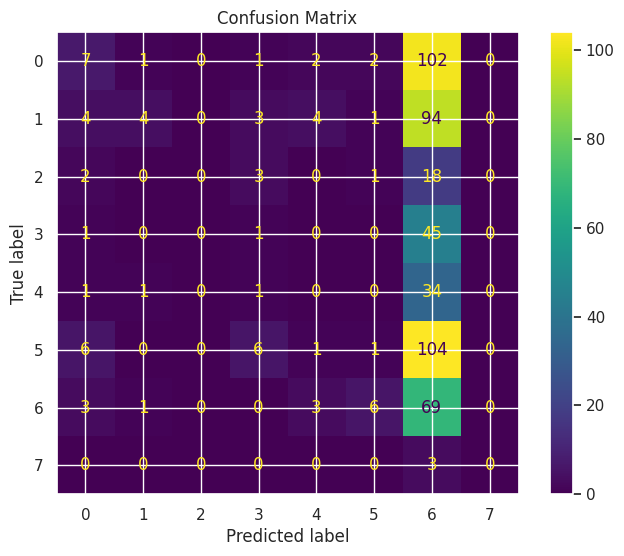

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_0
------------------------------
TRAIN
Accuracy: 0.3475
Precision: 0.3045
Recall: 0.3475
F1: 0.2928
Kappa: 0.1900
Error Rate: 0.6525

TEST
Accuracy: 0.0205
Precision: 0.1425
Recall: 0.0205
F1: 0.0176
Kappa: -0.0093
Error Rate: 0.9795
Gap (overfitting): 0.3270

CV
Mean: 0.3580
Std: 0.0241
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



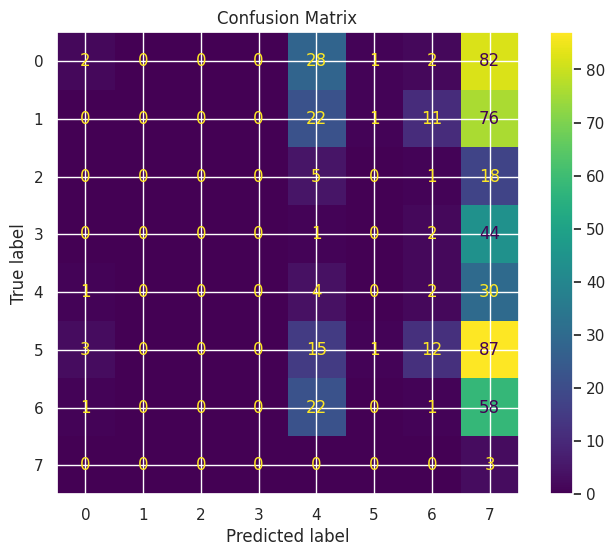

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_GRU_1e-1
------------------------------
TRAIN
Accuracy: 0.3499
Precision: 0.3319
Recall: 0.3499
F1: 0.2921
Kappa: 0.1914
Error Rate: 0.6501

TEST
Accuracy: 0.0205
Precision: 0.0545
Recall: 0.0205
F1: 0.0120
Kappa: -0.0194
Error Rate: 0.9795
Gap (overfitting): 0.3294

CV
Mean: 0.3535
Std: 0.0244
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.1, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



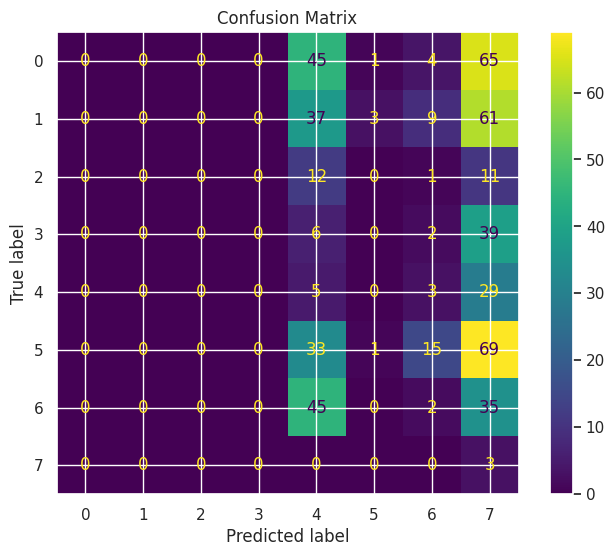

In [9]:
models_tcn_gru_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_tcn_gru_f2['TCN_GRU_adam'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f2['TCN_GRU_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f2['TCN_GRU_rmsprop'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================


# equivalente a hidden=10 (tcn=5, gru=5)
models_tcn_gru_f2['TCN_GRU_10'] = TCN_GRU_Hybrid(
    tcn_channels=[5], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=5, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=30 (tcn=8, gru=8)
models_tcn_gru_f2['TCN_GRU_30'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50 (tcn=16, gru=16)
models_tcn_gru_f2['TCN_GRU__50'] = TCN_GRU_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas TCN + 2 camadas GRU
models_tcn_gru_f2['TCN_GRU_50_16'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_tcn_gru_f2['TCN_GRU_0'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f2['TCN_GRU_1e-1'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.1, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru_f2, "tcn_gru2")



/tmp/ipykernel_520/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd
------------------------------
TRAIN
Accuracy: 0.4027
Precision: 0.3471
Recall: 0.4027
F1: 0.3643
Kappa: 0.2638
Error Rate: 0.5973

TEST
Accuracy: 0.1698
Precision: 0.0678
Recall: 0.1698
F1: 0.0865
Kappa: 0.0014
Error Rate: 0.8302
Gap (overfitting): 0.2329

CV
Mean: 0.3944
Std: 0.0499
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



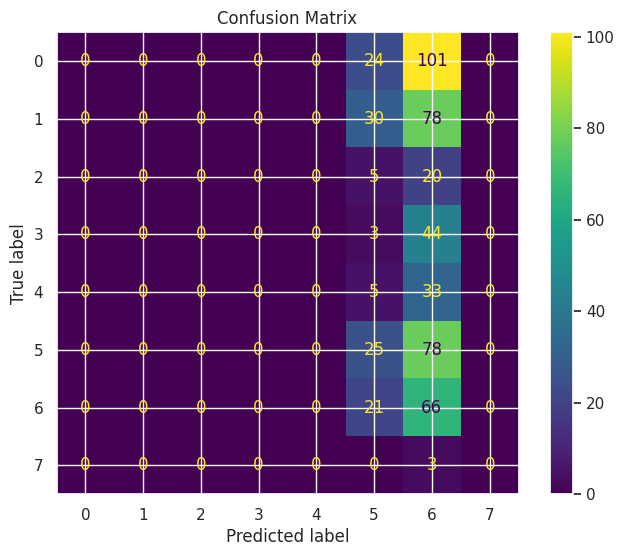

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_95
------------------------------
TRAIN
Accuracy: 0.5709
Precision: 0.5736
Recall: 0.5709
F1: 0.5390
Kappa: 0.4702
Error Rate: 0.4291

TEST
Accuracy: 0.2015
Precision: 0.0992
Recall: 0.2015
F1: 0.0979
Kappa: 0.0046
Error Rate: 0.7985
Gap (overfitting): 0.3694

CV
Mean: 0.5434
Std: 0.1157
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



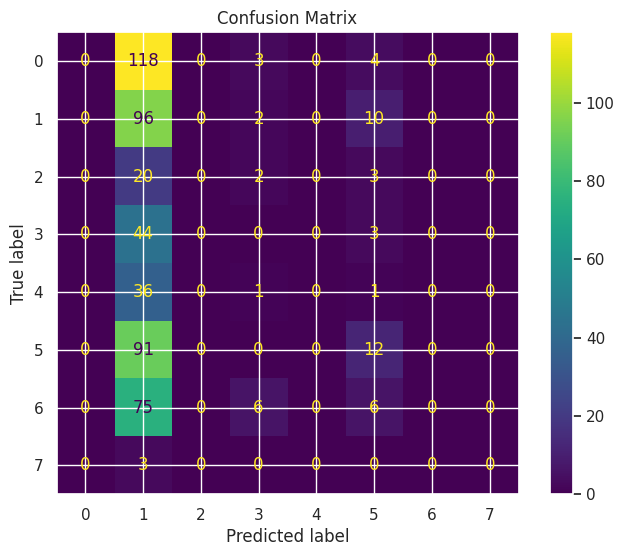

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd
------------------------------
TRAIN
Accuracy: 0.5268
Precision: 0.5333
Recall: 0.5268
F1: 0.4893
Kappa: 0.4196
Error Rate: 0.4732

TEST
Accuracy: 0.1343
Precision: 0.0787
Recall: 0.1343
F1: 0.0718
Kappa: -0.0420
Error Rate: 0.8657
Gap (overfitting): 0.3925

CV
Mean: 0.5490
Std: 0.0460
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



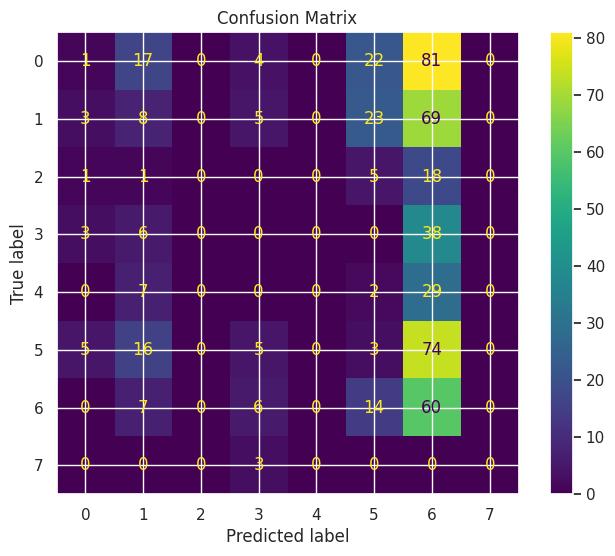


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_95
------------------------------
TRAIN
Accuracy: 0.8078
Precision: 0.8154
Recall: 0.8078
F1: 0.8042
Kappa: 0.7683
Error Rate: 0.1922

TEST
Accuracy: 0.1623
Precision: 0.2478
Recall: 0.1623
F1: 0.1036
Kappa: 0.0150
Error Rate: 0.8377
Gap (overfitting): 0.6455

CV
Mean: 0.7429
Std: 0.1458
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



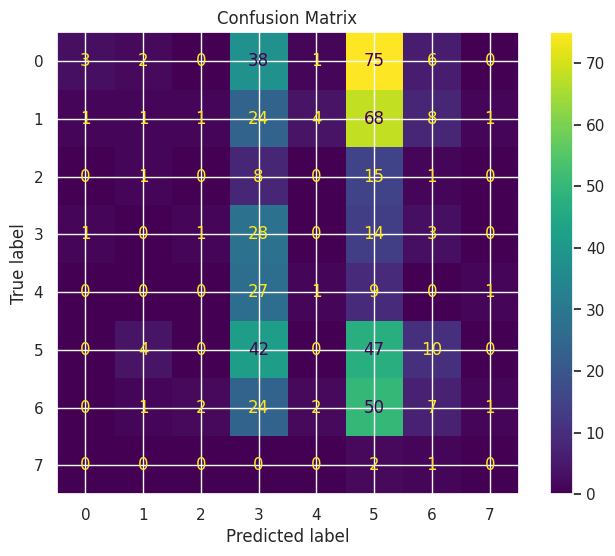

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: Fsgd
------------------------------
TRAIN
Accuracy: 0.8006
Precision: 0.8025
Recall: 0.8006
F1: 0.7874
Kappa: 0.7588
Error Rate: 0.1994

TEST
Accuracy: 0.1922
Precision: 0.1842
Recall: 0.1922
F1: 0.1466
Kappa: -0.0052
Error Rate: 0.8078
Gap (overfitting): 0.6085

CV
Mean: 0.7782
Std: 0.1246
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



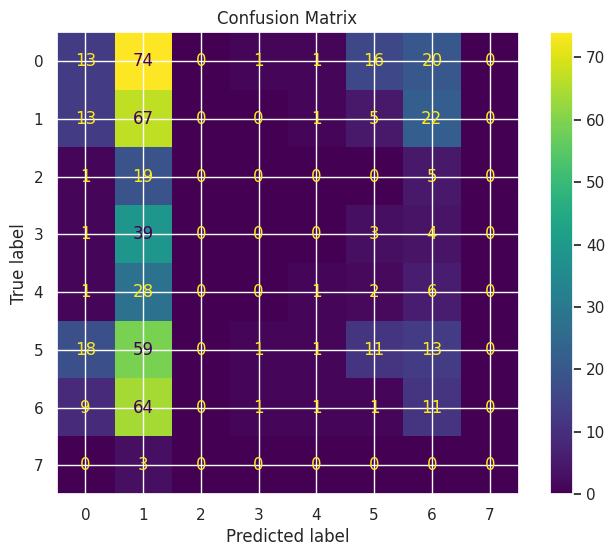

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_5095
------------------------------
TRAIN
Accuracy: 0.9528
Precision: 0.9478
Recall: 0.9528
F1: 0.9484
Kappa: 0.9430
Error Rate: 0.0472

TEST
Accuracy: 0.2313
Precision: 0.2189
Recall: 0.2313
F1: 0.2034
Kappa: 0.0619
Error Rate: 0.7687
Gap (overfitting): 0.7214

CV
Mean: 0.8667
Std: 0.1059
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



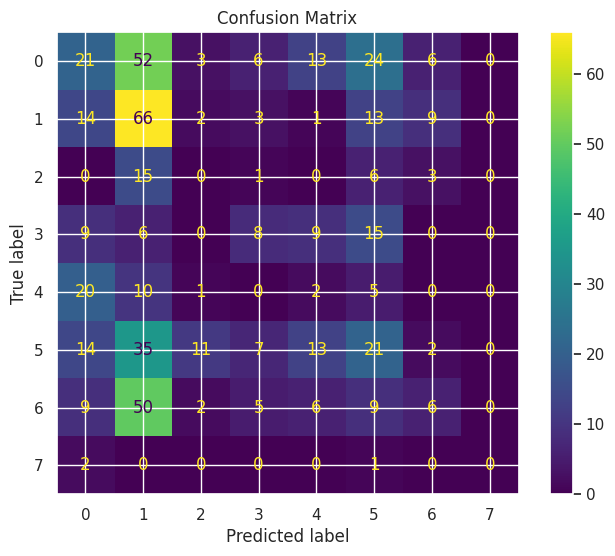

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_3e-4
------------------------------
TRAIN
Accuracy: 0.3363
Precision: 0.3015
Recall: 0.3363
F1: 0.2964
Kappa: 0.1730
Error Rate: 0.6637

TEST
Accuracy: 0.1716
Precision: 0.1745
Recall: 0.1716
F1: 0.0960
Kappa: 0.0144
Error Rate: 0.8284
Gap (overfitting): 0.1646

CV
Mean: 0.3261
Std: 0.0116
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



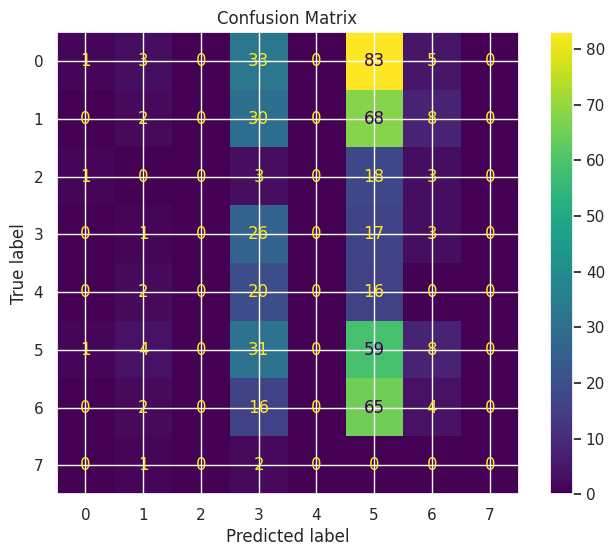

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_5_e-4
------------------------------
TRAIN
Accuracy: 0.4275
Precision: 0.3639
Recall: 0.4275
F1: 0.3858
Kappa: 0.2979
Error Rate: 0.5725

TEST
Accuracy: 0.1884
Precision: 0.0697
Recall: 0.1884
F1: 0.0644
Kappa: -0.0050
Error Rate: 0.8116
Gap (overfitting): 0.2391

CV
Mean: 0.4616
Std: 0.0385
------------------------------
Model params:
{'tcn_channels': [16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



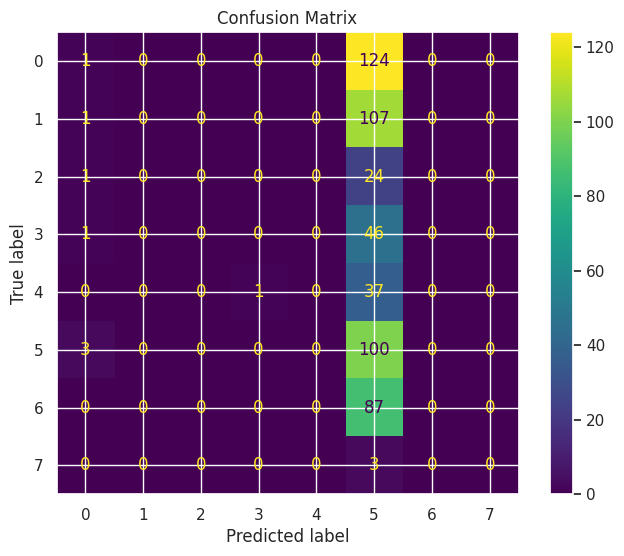

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16e-4
------------------------------
TRAIN
Accuracy: 0.4684
Precision: 0.4135
Recall: 0.4684
F1: 0.4062
Kappa: 0.3518
Error Rate: 0.5316

TEST
Accuracy: 0.1623
Precision: 0.2167
Recall: 0.1623
F1: 0.1490
Kappa: 0.0001
Error Rate: 0.8377
Gap (overfitting): 0.3061

CV
Mean: 0.4549
Std: 0.0110
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



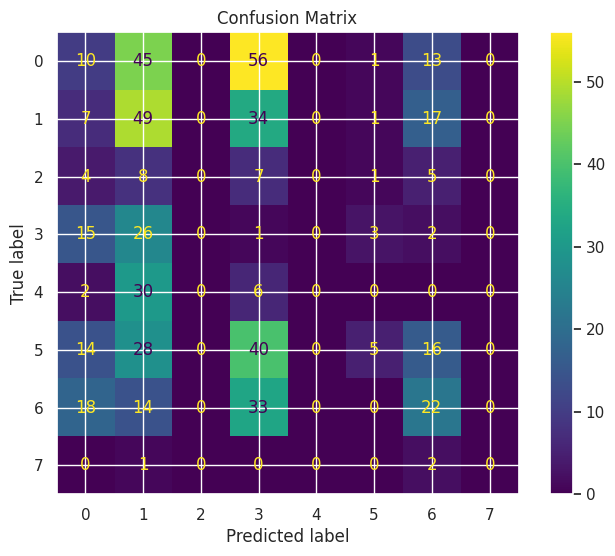

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
models_tcn_gru_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_tcn_gru_f3['F2_30_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_30_sgd_95'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_50_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_50_95'] = TCN_GRU_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['Fsgd'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_5095'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_tcn_gru_f3['F2_3e-4'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_5_e-4'] = TCN_GRU_Hybrid(
    tcn_channels=[16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=16, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_50_16e-4'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_tcn_gru_f3['F2_30_sgd2'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f3['F2_30_sgdLR'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru_f3, "tcngru3")

/tmp/ipykernel_5457/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16e-4
------------------------------
TRAIN
Accuracy: 0.4500
Precision: 0.3994
Recall: 0.4500
F1: 0.4191
Kappa: 0.3283
Error Rate: 0.5500

TEST
Accuracy: 0.1828
Precision: 0.0884
Recall: 0.1828
F1: 0.0999
Kappa: 0.0257
Error Rate: 0.8172
Gap (overfitting): 0.2671

CV
Mean: 0.4762
Std: 0.0112
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



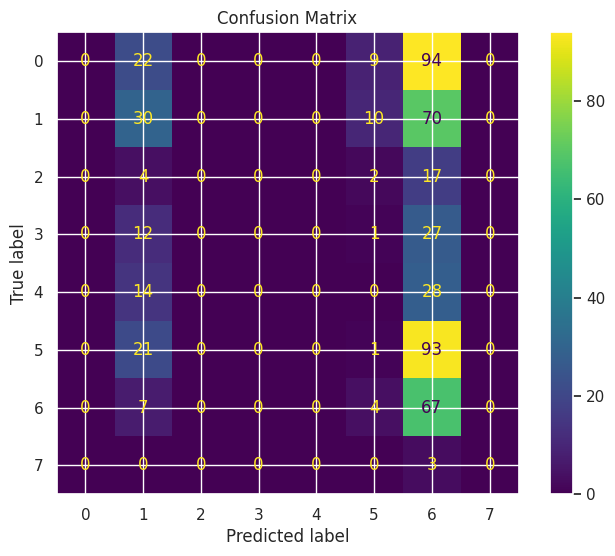

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd2
------------------------------
TRAIN
Accuracy: 0.3387
Precision: 0.3094
Recall: 0.3387
F1: 0.2882
Kappa: 0.1780
Error Rate: 0.6613

TEST
Accuracy: 0.0914
Precision: 0.0890
Recall: 0.0914
F1: 0.0560
Kappa: -0.0175
Error Rate: 0.9086
Gap (overfitting): 0.2473

CV
Mean: 0.3361
Std: 0.0200
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



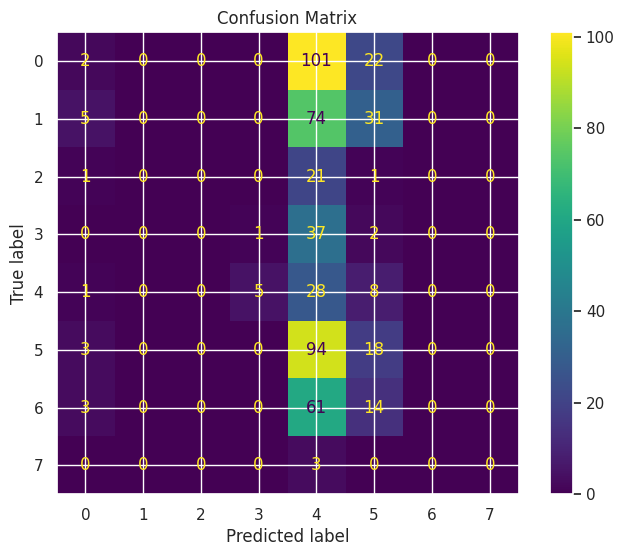

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgdLR
------------------------------
TRAIN
Accuracy: 0.2754
Precision: 0.2555
Recall: 0.2754
F1: 0.2069
Kappa: 0.0940
Error Rate: 0.7246

TEST
Accuracy: 0.1604
Precision: 0.1223
Recall: 0.1604
F1: 0.1101
Kappa: -0.0212
Error Rate: 0.8396
Gap (overfitting): 0.1150

CV
Mean: 0.2784
Std: 0.0179
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



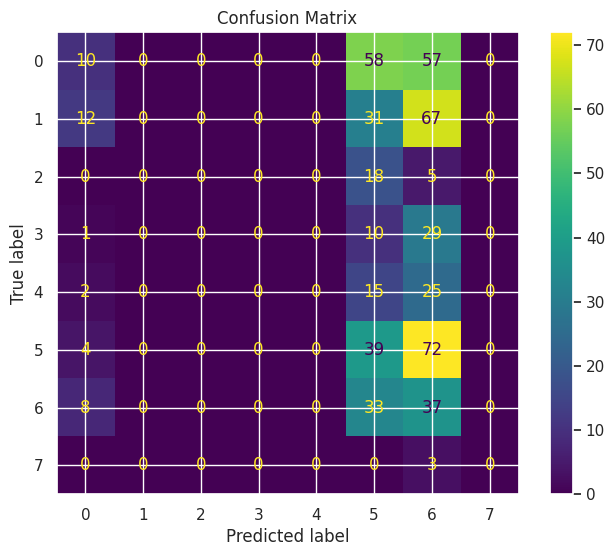

In [5]:
models_tcn_gru_f31 = {}
models_tcn_gru_f31['F2_50_16e-4'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_tcn_gru_f31['F2_30_sgd2'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f31['F2_30_sgdLR'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru_f31, "tcngru31")

/tmp/ipykernel_5457/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_e-3_sgd
------------------------------
TRAIN
Accuracy: 0.4948
Precision: 0.4833
Recall: 0.4948
F1: 0.4747
Kappa: 0.3811
Error Rate: 0.5052

TEST
Accuracy: 0.0690
Precision: 0.0081
Recall: 0.0690
F1: 0.0138
Kappa: 0.0016
Error Rate: 0.9310
Gap (overfitting): 0.4258

CV
Mean: 0.4549
Std: 0.0484
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



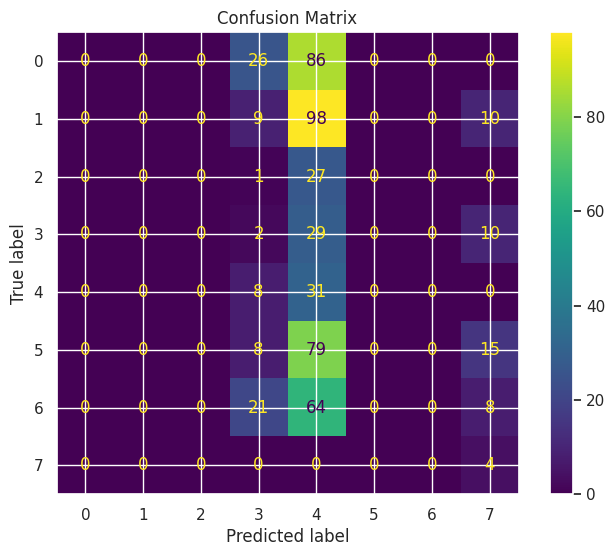

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F31e-4_sgd
------------------------------
TRAIN
Accuracy: 0.2970
Precision: 0.2036
Recall: 0.2970
F1: 0.2226
Kappa: 0.1078
Error Rate: 0.7030

TEST
Accuracy: 0.2407
Precision: 0.1074
Recall: 0.2407
F1: 0.1483
Kappa: 0.0349
Error Rate: 0.7593
Gap (overfitting): 0.0564

CV
Mean: 0.2818
Std: 0.0186
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



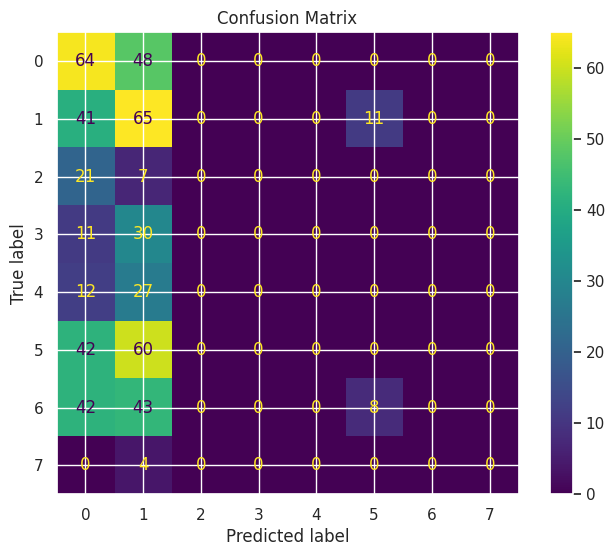

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F30e-3_sgd
------------------------------
TRAIN
Accuracy: 0.4388
Precision: 0.4680
Recall: 0.4388
F1: 0.4077
Kappa: 0.3099
Error Rate: 0.5612

TEST
Accuracy: 0.0728
Precision: 0.0054
Recall: 0.0728
F1: 0.0100
Kappa: -0.0014
Error Rate: 0.9272
Gap (overfitting): 0.3660

CV
Mean: 0.4162
Std: 0.0375
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.1, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



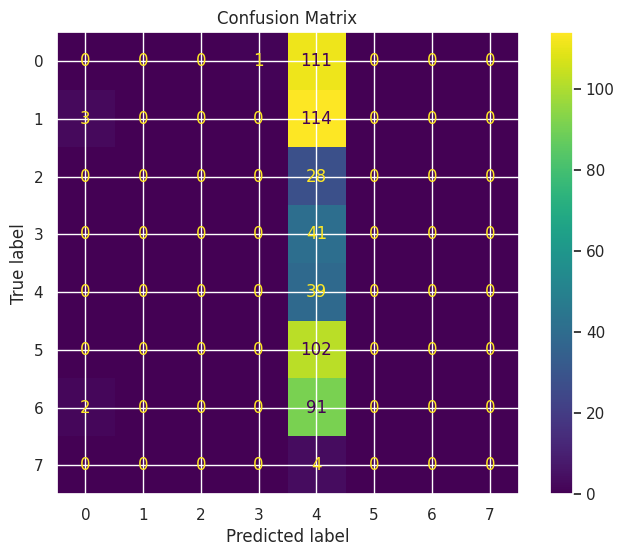

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3301e-32_sgd
------------------------------
TRAIN
Accuracy: 0.3747
Precision: 0.4026
Recall: 0.3747
F1: 0.3367
Kappa: 0.2326
Error Rate: 0.6253

TEST
Accuracy: 0.0821
Precision: 0.0165
Recall: 0.0821
F1: 0.0229
Kappa: 0.0190
Error Rate: 0.9179
Gap (overfitting): 0.2926

CV
Mean: 0.3686
Std: 0.0239
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



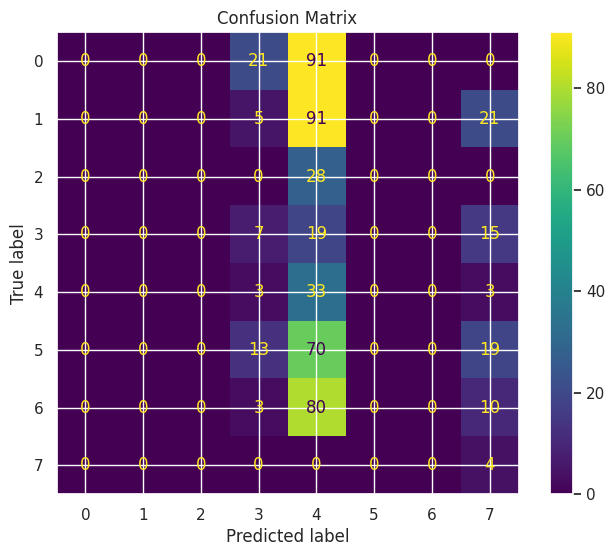

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3305e-42_sgd
------------------------------
TRAIN
Accuracy: 0.3122
Precision: 0.2744
Recall: 0.3122
F1: 0.2706
Kappa: 0.1452
Error Rate: 0.6878

TEST
Accuracy: 0.0858
Precision: 0.3075
Recall: 0.0858
F1: 0.0328
Kappa: 0.0125
Error Rate: 0.9142
Gap (overfitting): 0.2264

CV
Mean: 0.3025
Std: 0.0167
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



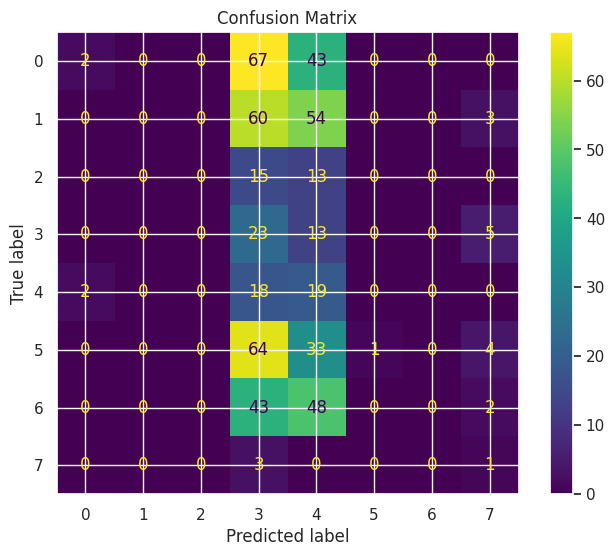

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_16-30_sgd
------------------------------
TRAIN
Accuracy: 0.7910
Precision: 0.8061
Recall: 0.7910
F1: 0.7759
Kappa: 0.7443
Error Rate: 0.2090

TEST
Accuracy: 0.1791
Precision: 0.1576
Recall: 0.1791
F1: 0.0810
Kappa: 0.0140
Error Rate: 0.8209
Gap (overfitting): 0.6119

CV
Mean: 0.7608
Std: 0.1303
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



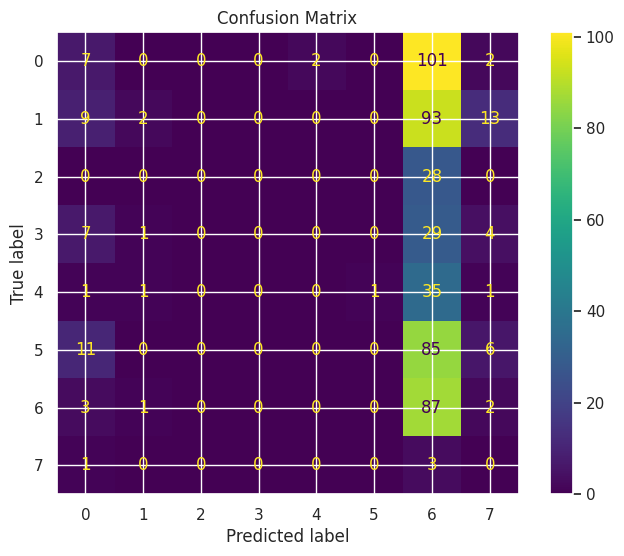

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_16_sgd
------------------------------
TRAIN
Accuracy: 0.2410
Precision: 0.1109
Recall: 0.2410
F1: 0.1316
Kappa: 0.0300
Error Rate: 0.7590

TEST
Accuracy: 0.2108
Precision: 0.3001
Recall: 0.2108
F1: 0.0827
Kappa: 0.0028
Error Rate: 0.7892
Gap (overfitting): 0.0302

CV
Mean: 0.2577
Std: 0.0243
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.0, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



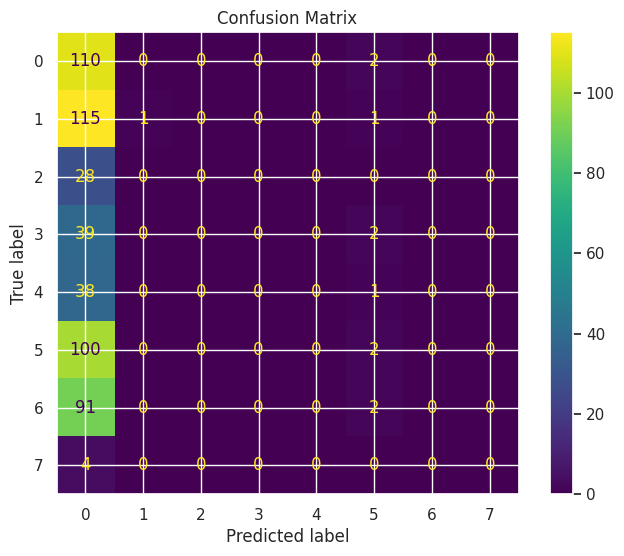

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_sgd
------------------------------
TRAIN
Accuracy: 0.4163
Precision: 0.3585
Recall: 0.4163
F1: 0.3794
Kappa: 0.2879
Error Rate: 0.5837

TEST
Accuracy: 0.1716
Precision: 0.0507
Recall: 0.1716
F1: 0.0633
Kappa: -0.0070
Error Rate: 0.8284
Gap (overfitting): 0.2447

CV
Mean: 0.4459
Std: 0.0376
------------------------------
Model params:
{'tcn_channels': [16, 16], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1, 2], 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



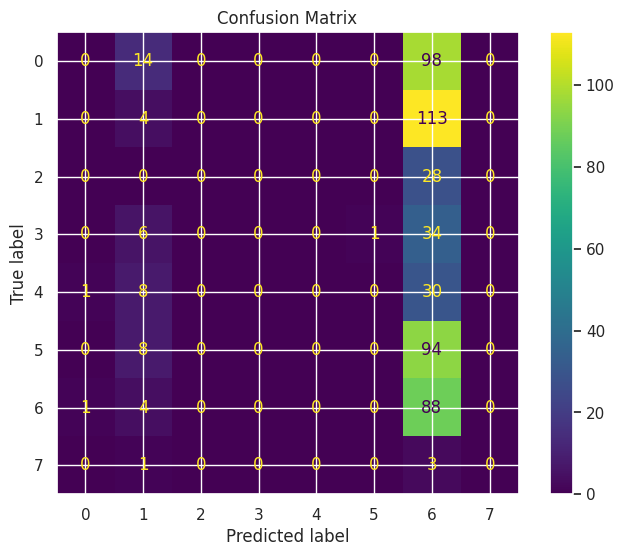

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30adam
------------------------------
TRAIN
Accuracy: 0.3291
Precision: 0.2894
Recall: 0.3291
F1: 0.2882
Kappa: 0.1690
Error Rate: 0.6709

TEST
Accuracy: 0.0112
Precision: 0.2090
Recall: 0.0112
F1: 0.0075
Kappa: -0.0017
Error Rate: 0.9888
Gap (overfitting): 0.3179

CV
Mean: 0.3171
Std: 0.0208
------------------------------
Model params:
{'tcn_channels': [8], 'tcn_kernel': 3, 'tcn_dropout': 0.2, 'tcn_dilations': [1], 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



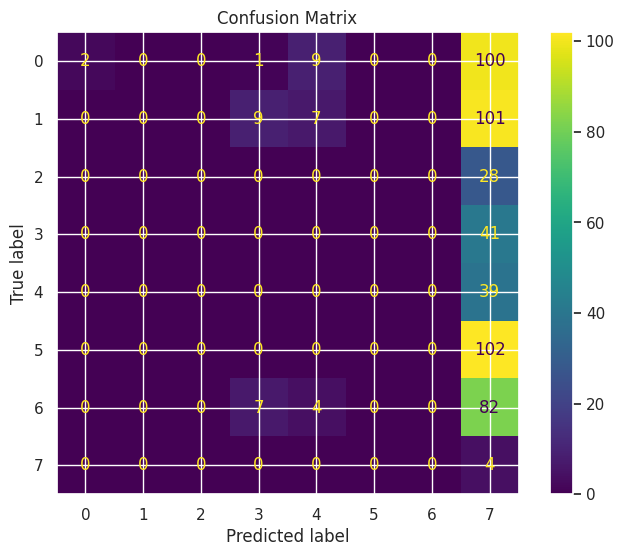

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
models_tcn_gru_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================


models_tcn_gru_f4['F3_e-3_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f4['F31e-4_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f4['F30e-3_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.1, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f4['F3301e-32_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_tcn_gru_f4['F3305e-42_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com arquitetura 50_16 (2 camadas)
# ============================================================


models_tcn_gru_f4['F3_50_16-30_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)



models_tcn_gru_f4['F3_50_16_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.0, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f4['F3_50_sgd'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.2, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================


models_tcn_gru_f4['F3_30adam'] = TCN_GRU_Hybrid(
    tcn_channels=[8], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1],
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_gru_f4['F3_50_16adam'] = TCN_GRU_Hybrid(
    tcn_channels=[16, 16], tcn_kernel=3, tcn_dropout=0.2, tcn_dilations=[1, 2],
    gru_hidden=16, gru_layers=2, gru_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_gru_f4, "tcn_ruf4")